#  Small-scale snow cover variability and its effect on ground surface temperatures in West Greenland

Sofia Rosa Bauriedl and Brian Groenke

Models implemented for the paper: "Small-scale snow cover variability and its effect on ground surface temperatures in West Greenland"

To quantify relationships between snowpack properties, topography and ground surface temperature, we
developed Bayesian regression models. As the response variable, we used mean ground surface temperature from
Febrary to March 2024.
Prior to model fitting, we transformed and rescaled all predictors to improve interpretability and numerical stability. We centered snow density, the topographic predictors, and soil moisture on their means, but left snow depth uncentered, so that the intercept of every model that includes snow depth represents the ground surface temperature without snow and can be given a physically motivated prior based on the mean air temperature. 
We tested multiple models to predict ground surface temperature, using different combinations
f snow depth, snow density, and topographic predictors (slope, elevation, and aspect). We conducted prior
predictive checks to confirm that priors resulted in plausible predicted ground surface temperature
ranges.
We obtained approximate samples from the posterior distribution for each model using the default configuration of the No-U-Turn sampler of (Hoffman and Gelman 2011). We also retained point-wise log-likelihood values to enable model comparison. 
To evaluate model performance and select the most informative predictors, we compared all
models using leave-one-out cross-validation (LOO).


> **Revision 1.** This version of `Bayesian_models_rev0.ipynb` centers (but does not rescale) snow density, the topographic predictors, and soil moisture, so that coefficient units and slope priors are unchanged. Snow depth stays uncentered in every model, so in models that include depth the intercept `alpha` is still the surface temperature without snow, averaged over the observed densities and topography, and keeps the physically motivated prior $\mathcal{N}_\infty^{0.3}(-13.2, 1.5)$. In models without depth, the intercept is the temperature at the mean predictor values, under snow, so it gets a weakly informative prior $\mathcal{N}_\infty^{0.3}(-5, 5)$ around the observed mean instead. In rev0, the intercept prior acted on uncentered density and topography, which produced spurious effects of density and elevation in the models without depth; see the review section for details. Bayesian R² is now computed from the posterior draws of the expected value `mu`, following Gelman et al. (2019); rev0 computed it from posterior predictive draws, whose residual noise pulls R² toward intermediate values regardless of model skill (see `compute_bayesian_r2`).

In [1]:
# data
import numpy as np
import pandas as pd

# stats / inference
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import scipy.stats as stats
import arviz as az

# plotting
import matplotlib.pyplot as plt
import seaborn as sns

## Data

In [2]:
df = pd.read_csv("sensor_data.csv")
model_vars = ['snow_depth', 'bulk_density', 'T_surface', 'topography', 'vegetation', 'TMS_ID', 'elevation', 'aspect', 'slope','soil_moisture']  
df = df.dropna(subset=model_vars).copy()


The columns *tomst_id*, *sr_nr*, *TMS_ID*, *Transect*, *Plot*, *Lat* and *Lon* identify the individual Temperature-Moisture-Sensor (TMS/Tomst) and its associated sampling location within the study design. 

Topographic characteristics of the sensor locations include *slope* (°), *aspect* (°), and *elevation* (m a.s.l.), which were derived from a digital terrain model. Each sensor location was additionally assigned to a categorical *topography* class based on geomorphological position (not used on this analysis).

Vegetation conditions at each sensor location were determined from field vegetation and moisture surveys and classified into four vegetation categories represented by the variable *vegetation*.

Snow properties were derived from SnowMicroPen measurements collected in April 2024. Multiple SMP profiles were obtained around each sensor. *snow_depth* represents the mean snow depth (m) and *bulk_density* represents the mean snow density (dimensionless metric proportional to volumetric ice content), associated with each sensor location.

*T_surface* represents the mean ground surface temperature measured by the sensors during February and March 2024. 
*soil_moisture* corresponds to the last available volumetric soil moisture measurement recorded before soil freeze-up. 

In [3]:
df

,tomst_id,sr_nr,TMS_ID,Transect,Plot,Lat,Lon,vegetation,topography,slope,elevation,aspect,snow_depth,bulk_density,T_surface,tms_id,soil_moisture
0,6,94231022,A,3,1,69.278881,-53.479375,dry tundra,footslope,2.66,88.00,6.63,0.81,0.307,-5.303336,94231022,0.270004
1,7,94231023,B,3,2,69.278717,-53.477737,dry shrub,footslope,4.90,90.29,269.73,0.59,0.297,-3.170914,94231023,0.245999
2,8,94231024,C,3,2,69.278723,-53.477548,moist tundra,plain,0.47,90.58,261.64,0.74,0.286,-4.272328,94231024,0.493143
3,15,94231031,E,3,4,69.278654,-53.474111,dry tundra,footslope,4.25,106.26,198.99,0.36,0.272,-9.896081,94231031,0.230189
4,16,94231032,H,1,1,69.267720,-53.466919,moist tundra,footslope,3.27,86.50,320.75,0.57,0.289,-1.628434,94231032,0.599245
5,19,94231035,I,1,2,69.268028,-53.466093,moist tundra,footslope,2.06,88.11,285.21,0.68,0.295,-3.871153,94231035,0.548203
6,20,94231036,J,1,2,69.267811,-53.466177,moist shrub,plain,0.68,87.93,146.00,0.48,0.289,-5.077051,94231036,0.422474
7,23,94231039,K,1,3,69.268148,-53.464995,dry shrub,footslope,2.75,90.99,313.23,0.59,0.286,-4.861922,94231039,0.210919
8,25,94231041,L,1,4,69.268748,-53.462484,dry tundra,footslope,2.60,109.87,278.80,0.56,0.299,-4.890992,94231041,0.256649
9,26,94231042,M,1,4,69.268695,-53.462354,moist shrub,hillslope,19.58,110.26,207.71,0.50,0.305,-4.980452,94231042,0.431098


In [4]:
df["slope"] = pd.to_numeric(df["slope"], errors="coerce")
df["snow_depth"] = pd.to_numeric(df["snow_depth"], errors="coerce")
df["bulk_density"] = pd.to_numeric(df["bulk_density"], errors="coerce")
df["elevation"] = pd.to_numeric(df["elevation"], errors="coerce")


# 1) Snow depth: scale to decimeters (1 per 10 cm)
df["snow_10cm"] = df["snow_depth"] / 0.1

# 2) Bulk density: scale per 10% of water density (or per 10g/cm^3)
df["density_01"] = df["bulk_density"] / 0.1

# 3) Elevation: scale per 10 m
df["elev_10m"] = df["elevation"] / 10

# 4) Slope: keep per 1 degree 

# 5) Aspect: convert to sin and cos (already bounded -1 to 1)
df["aspect_rad"] = np.radians(df["aspect"])
df["aspect_sin"] = np.sin(df["aspect_rad"])
df["aspect_cos"] = np.cos(df["aspect_rad"])

In [5]:
# Centered predictors (snow depth stays uncentered so that alpha is the
# surface temperature under zero snow)
for col in ['density_01', 'slope', 'elev_10m', 'aspect_sin', 'aspect_cos']:
    df[col + "_c"] = df[col] - df[col].mean()

## Define functions

In [6]:
def sample_prior(model, draws = 1000, random_seed=20240409):
    with model:
        # Prior predictive
        prior = pm.sample_prior_predictive(draws, random_seed=random_seed)
    return prior

In [7]:
def run_model(model, draws=3000, tune=3000, prior_draws=1000, target_accept=0.9, random_seed=20240409):
    """
    Runs prior predictive, posterior sampling,
    and posterior predictive sampling for a PyMC model.
    
    Returns:
        prior, idata
    """
    
    prior = sample_prior(model, prior_draws, random_seed)
    
    with model:
        
        # Posterior sampling
        idata = pm.sample(
            draws,
            tune=tune,
            target_accept=target_accept,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            random_seed=random_seed
        )
        
        # Posterior predictive
        idata = pm.sample_posterior_predictive(
            idata,
            extend_inferencedata=True
        )
    
    return prior, idata


In [8]:
def plot_all_prior_coefficients(prior, group="prior"):
    
    vars_in_model = list(prior[group].data_vars)
    
    vars_to_plot = [
        v for v in vars_in_model
        if v.startswith("beta_") or v.startswith("sigma_")
    ]
    
    az.plot_density(
        prior,
        group=group,
        var_names=vars_to_plot
    )

In [9]:
def summarize_all_prior_coefficients(prior, group="prior", round_to=2):
    
    vars_in_model = list(prior[group].data_vars)
    

    vars_to_summarize = [
        v for v in vars_in_model
        if (
            v == "alpha"
            or v == "sigma"
            or v.startswith("beta_")
            or v.startswith("sigma_")
        )
    ]
    
    if len(vars_to_summarize) == 0:
        print("No matching prior coefficients found.")
        return None
    
    summary = az.summary(
        prior,
        group=group,
        var_names=vars_to_summarize,
        round_to=round_to
    )
    
    return summary


In [10]:
def summarize_all_posterior_coefficients(idata, group="posterior", round_to=2):
    
    vars_in_model = list(idata[group].data_vars)
    
    vars_to_summarize = [
        v for v in vars_in_model
        if (
            v == "alpha"
            or v == "sigma"
            or v.startswith("beta_")
            or v.startswith("sigma_")
        )
    ]
    
    if len(vars_to_summarize) == 0:
        print("No matching variables found.")
        return None
    
    summary = az.summary(
        idata,
        var_names=vars_to_summarize,
        group=group,
        round_to=round_to
    )
    
    return summary


In [11]:
def plot_all_posterior_coefficients(idata, group="posterior"):
    
    vars_in_model = list(idata[group].data_vars)
    
    vars_to_plot = [
        v for v in vars_in_model
        if (
            v == "alpha"
            or v == "sigma"
            or v.startswith("beta_")
        )
    ]
    
    if len(vars_to_plot) == 0:
        print("No matching posterior coefficients found.")
        return
    
    az.plot_posterior(
        idata,
        group=group,
        var_names=vars_to_plot
    )

In [12]:
def plot_residual_qq(idata, y_observed, var_name="T_surface"):
    """
    Compute posterior mean predictions and plot QQ plot of residuals.
    
    idata: InferenceData with posterior_predictive
    y_observed: observed response array
    var_name: name of predicted variable
    """
    
    # Posterior mean predictions
    y_pred = idata.posterior_predictive[var_name].mean(
        dim=("chain", "draw")
    ).values
    
    residuals = y_observed - y_pred
    
    stats.probplot(residuals, dist="norm", plot=plt)
    plt.title(f"QQ Plot of Residuals ({var_name})")
    plt.show()
    
    return residuals

In [13]:
def compute_bayesian_r2(idata, y_observed, var_name="mu"):
    """
    Compute Bayesian R² (Gelman et al. 2019) from the posterior draws of the
    expected value `mu`. Returns DataFrame with mean and SD.

    Earlier versions passed posterior predictive draws to `az.r2_score`, as in the
    ArviZ docstring example. Predictive draws include the residual noise, which
    inflates the variance of the predictions: a model with no predictive skill
    at all would still get R² of about 0.3. Gelman et al. define R² in terms of
    the expected value E(y | X, theta) for each posterior draw, which is what
    `mu` stores.
    """

    # Stack chains and draws
    y_pred = idata.posterior[var_name]
    y_pred = y_pred.stack(sample=("chain", "draw")).values.T  # shape (samples, obs)

    r2 = az.r2_score(y_observed, y_pred)

    r2_table = pd.DataFrame({
        "R2_mean": [float(r2["r2"])],
        "R2_sd": [float(r2["r2_std"])]
    })

    return r2_table


In [14]:
def compute_loo(idata, var_name = "T_surface"):
    """
    Compute LOO and return ArviZ LOO object.
    """
    loo = az.loo(idata, var_name = "T_surface")
    return loo


In [15]:
def plot_prior_predictions(prior, var="T_surface"):
    """
    Plot prior predictive distributions for each observation
    along with the actual observed data.
    
    prior: ArviZ InferenceData object returned by pm.sample_prior_predictive()
    var: the name of the predicted variable
    """
    
    # Prior predictive samples
    pred = prior.prior_predictive[var]
 
    obs = prior.observed_data[var].values if "observed_data" in prior.groups() else None
    
    pred_df = pred.to_dataframe().reset_index()
    
    fig, ax = plt.subplots(figsize=(8,5))
    
    # Boxplot of prior predictive distributions
    sns.boxplot(
        data=pred_df,
        x=f"{var}_dim_0",  # x-axis = observation index
        y=var,
        ax=ax
    )
    
    if obs is not None:
        ax.scatter(
            range(len(obs)),
            obs,
            color="red",
            marker="*",
            zorder=10,
            label="Observed"
        )
    
    ax.set_title("Prior Predictive Distribution")
    ax.set_xlabel("Observation index")
    ax.set_ylabel(var)
    if obs is not None:
        ax.legend()
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    return fig, ax


In [16]:
def plot_predictions(idata, var="T_surface", dim="T_surface_dim_0"):
    
    pred = idata.posterior_predictive[var]
    obs = idata.observed_data[var]
    
    pred_df = pred.to_dataframe().reset_index()
    
    fig, ax = plt.subplots(figsize=(8,5))
    
    sns.boxplot(
        data=pred_df,
        x=dim,
        y=var,
        ax=ax
    )
    
    ax.scatter(
        range(len(obs)),
        obs,
        color="red",
        marker="*",
        zorder=10,
        label="Observed"
    )
    
    ax.set_title("Posterior Predictive Distribution")
    ax.set_xlabel("Observation index")
    ax.set_ylabel(var)
    ax.legend()
    
    return fig, ax


In [17]:
def qqplot(idata, var="T_surface"):
    
    pred = idata.posterior_predictive[var]
    obs = idata.observed_data[var]
    
    qhi = pred.quantile(0.97, dim=["chain","draw"])
    qlo = pred.quantile(0.03, dim=["chain","draw"])
    qmid = pred.median(dim=["chain","draw"])
    
    plt.figure(figsize=(6,6))
    plt.axline((0,0), slope=1, c='black')
    
    plt.errorbar(
        obs,
        qmid,
        yerr=np.stack([qmid - qlo, qhi - qmid]),
        fmt="o"
    )
    
    lo = float(min(qlo.min(), obs.min()))
    hi = float(max(qhi.max(), obs.max()))
    
    plt.xlim((lo,hi))
    plt.ylim((lo,hi))
    
    plt.xlabel("Observed")
    plt.ylabel("Predicted")
    plt.title("QQ Plot")
    plt.show()


# Bayesian Models (MCMC)
- model: depth 
- model: topography 
- model: density 
- model: depth density
- model: depth topography
- model: density topography
- model: depth density toppgraphy
- model: depth model with uninformative priors
- model: depth model grouped by vegetation 

## model_depth

In [18]:
T_surface = df["T_surface"].values

with pm.Model() as model_depth:

    # -------------------------
    # Data
    # -------------------------
    snow = pm.Data("snow", df["snow_10cm"].values)       

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,        # mean air temperature, physically surface = air when snow = 0
        sigma=1.5,      
        upper=0.3       # truncate at upper bound of surface temp (0.3°C = sensor accuracy)
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,         #
        sigma=1
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_snow * snow
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C, sensor accuracy)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [19]:
model_depth_prior, model_depth_idata = run_model(model_depth)

Sampling: [T_surface, alpha, beta_snow, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_snow, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 4 seconds.


Sampling: [T_surface]


Output()

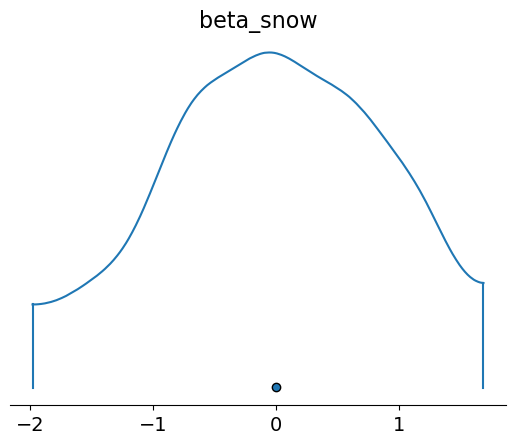

In [20]:
plot_all_prior_coefficients(model_depth_prior)

In [21]:
prior_summary = summarize_all_prior_coefficients(model_depth_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_snow,-0.00,0.98,-1.98,1.69,0.03,0.02,949.33,983.44,NaN
alpha,-13.21,1.52,-16.38,-10.41,0.05,0.04,923.07,943.76,NaN


In [22]:
summary = summarize_all_posterior_coefficients(model_depth_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.25,0.24,0.81,1.71,0.00,0.00,3722.88,4668.21,1.0
alpha,-12.28,1.22,-14.54,-9.99,0.02,0.01,3726.15,4644.84,1.0
sigma,2.07,0.60,1.20,3.15,0.01,0.02,4704.87,4642.77,1.0


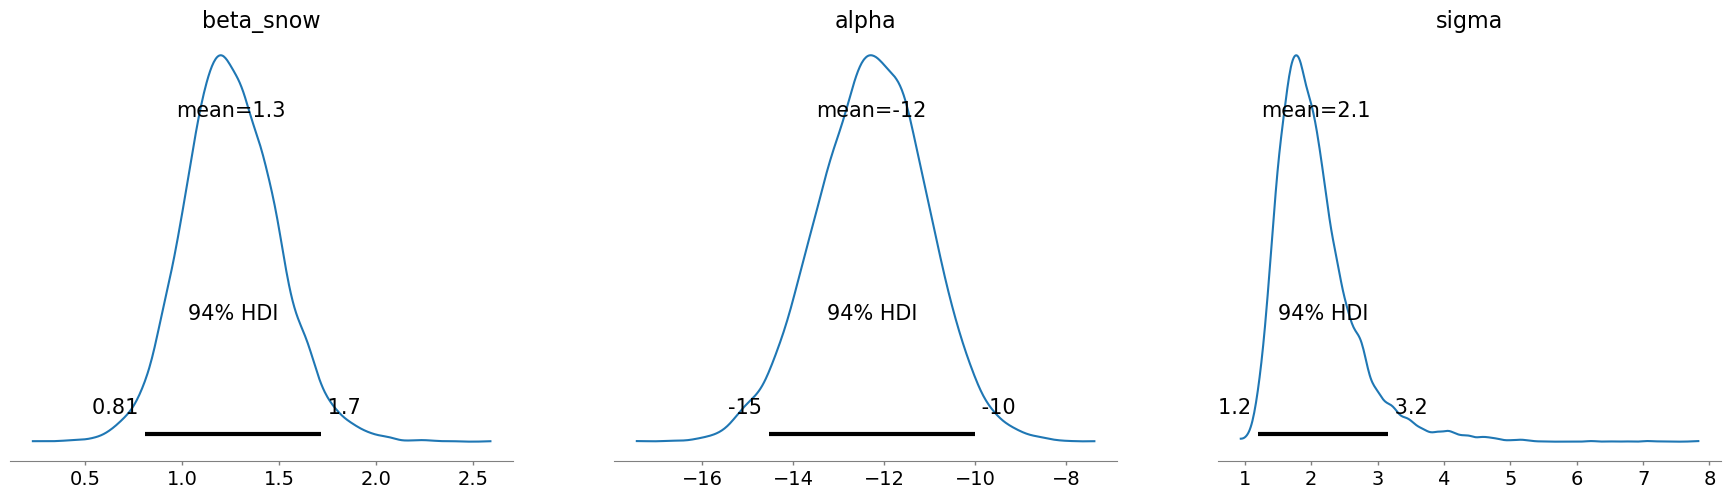

In [23]:
plot_all_posterior_coefficients(model_depth_idata)

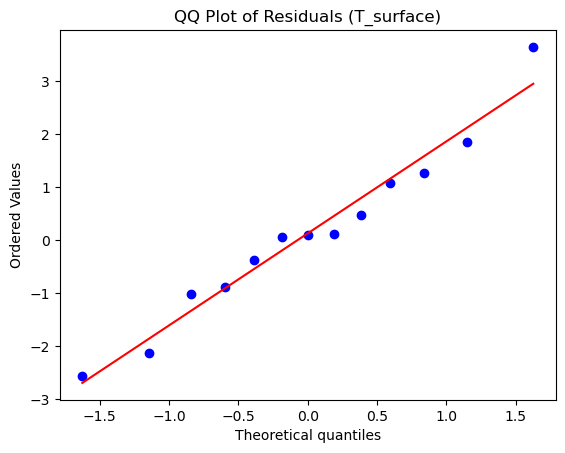

In [24]:
residuals = plot_residual_qq(
    model_depth_idata,
    T_surface,
    var_name="T_surface"
)

In [25]:
r2_table = compute_bayesian_r2(
    model_depth_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.542714,0.082721


In [26]:
loo_depth = compute_loo(model_depth_idata)
print(loo_depth)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -27.79     2.56
p_loo        2.42        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       13  100.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%



(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

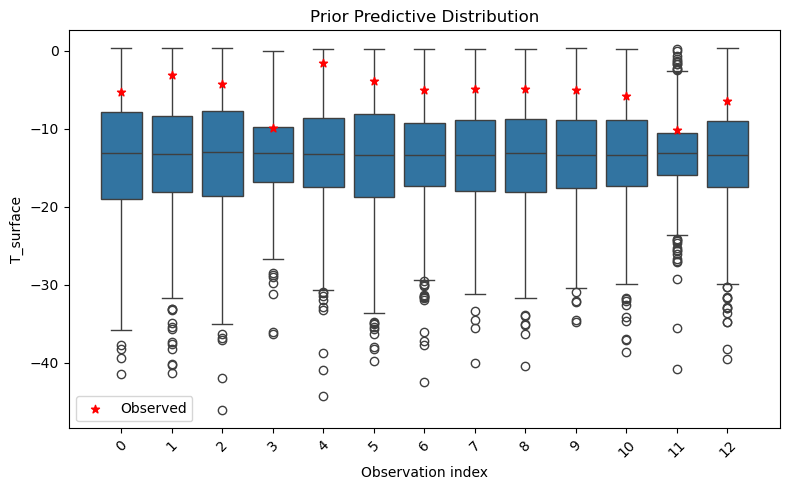

In [27]:
plot_prior_predictions(model_depth_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

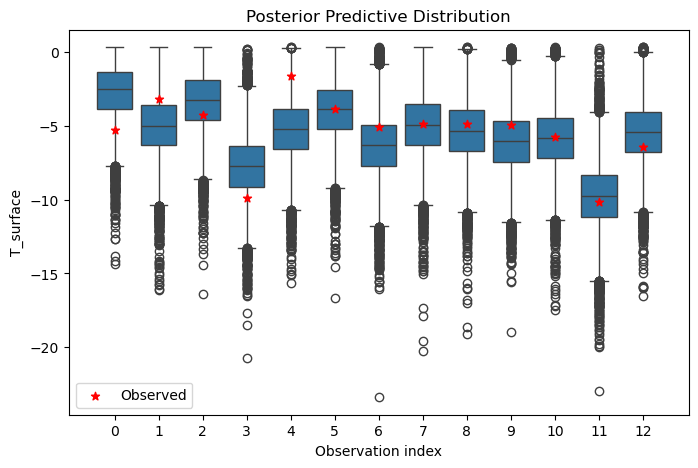

In [28]:
plot_predictions(model_depth_idata)

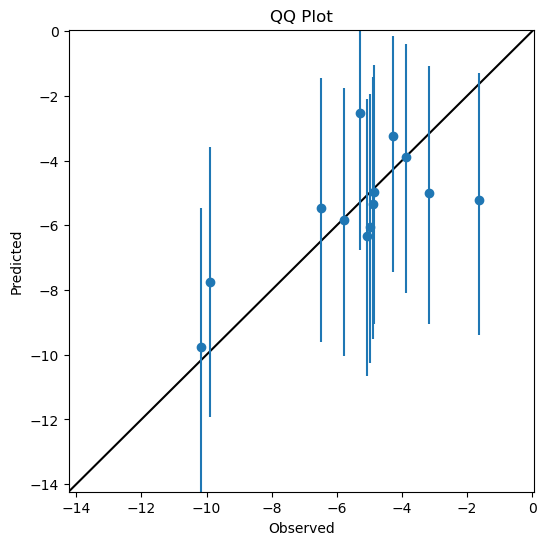

In [29]:
qqplot(model_depth_idata)

## model_topography

In [30]:
T_surface = df["T_surface"].values

with pm.Model() as model_topography:

    # -------------------------
    # Data
    # -------------------------
    slope = pm.Data("slope", df["slope_c"].values)
    elev = pm.Data("elev", df["elev_10m_c"].values)
    asp_sin = pm.Data("asp_sin", df["aspect_sin_c"].values)
    asp_cos = pm.Data("asp_cos", df["aspect_cos_c"].values)

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-5,  # temperature at mean predictor values, under snow
        sigma=5,
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_slope = pm.Normal(
        "beta_slope",
        mu=0.0,       
        sigma=0.5       
    )

    beta_elev = pm.Normal(
        "beta_elev",
        mu=0.0,
        sigma=0.5
    )

    beta_sin = pm.Normal(
        "beta_sin",
        mu=0.0,
        sigma=0.5
    )

    beta_cos = pm.Normal(
        "beta_cos",
        mu=0.0,
        sigma=0.5
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_slope * slope
        + beta_elev * elev
        + beta_sin * asp_sin
        + beta_cos * asp_cos
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [31]:
model_topography_prior, model_topography_idata = run_model(model_topography)

Sampling: [T_surface, alpha, beta_cos, beta_elev, beta_sin, beta_slope, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_slope, beta_elev, beta_sin, beta_cos, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 5 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


Sampling: [T_surface]


Output()

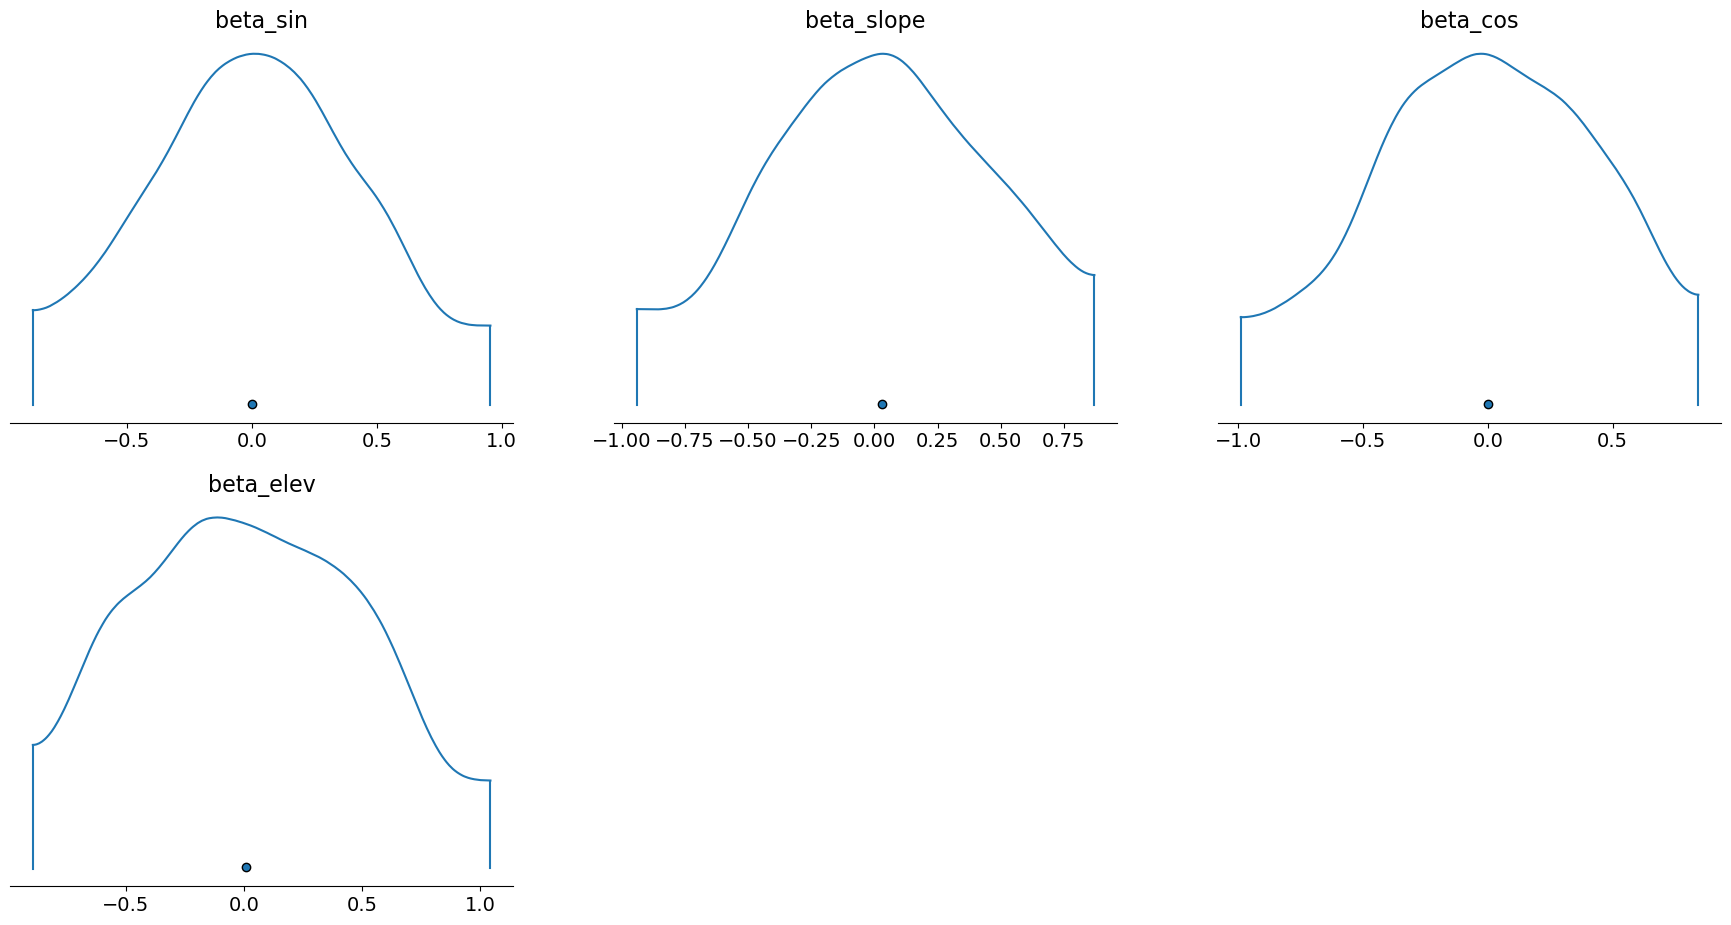

In [32]:
plot_all_prior_coefficients(model_topography_prior)

In [33]:
prior_summary = summarize_all_prior_coefficients(model_topography_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_sin,0.00,0.49,-0.88,0.96,0.02,0.01,930.37,930.87,NaN
beta_slope,0.03,0.50,-0.94,0.87,0.02,0.01,1008.75,982.80,NaN
beta_cos,-0.00,0.49,-0.99,0.85,0.02,0.01,949.33,983.44,NaN
beta_elev,0.01,0.53,-0.90,1.05,0.02,0.01,1020.11,778.10,NaN
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
alpha,-6.38,3.98,-13.41,0.24,0.13,0.09,971.08,900.63,NaN


In [34]:
summary = summarize_all_posterior_coefficients(model_topography_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_slope,0.07,0.21,-0.33,0.47,0.00,0.00,8076.19,6898.65,1.0
beta_elev,-0.16,0.46,-1.03,0.69,0.01,0.00,8149.53,7685.38,1.0
beta_sin,-0.21,0.49,-1.09,0.73,0.01,0.00,7577.41,5913.28,1.0
beta_cos,0.09,0.47,-0.80,0.94,0.01,0.00,7993.45,7785.52,1.0
alpha,-4.85,1.22,-6.92,-2.25,0.02,0.02,5399.82,3136.52,1.0
sigma,3.21,1.08,1.58,5.24,0.02,0.02,3810.60,5191.13,1.0


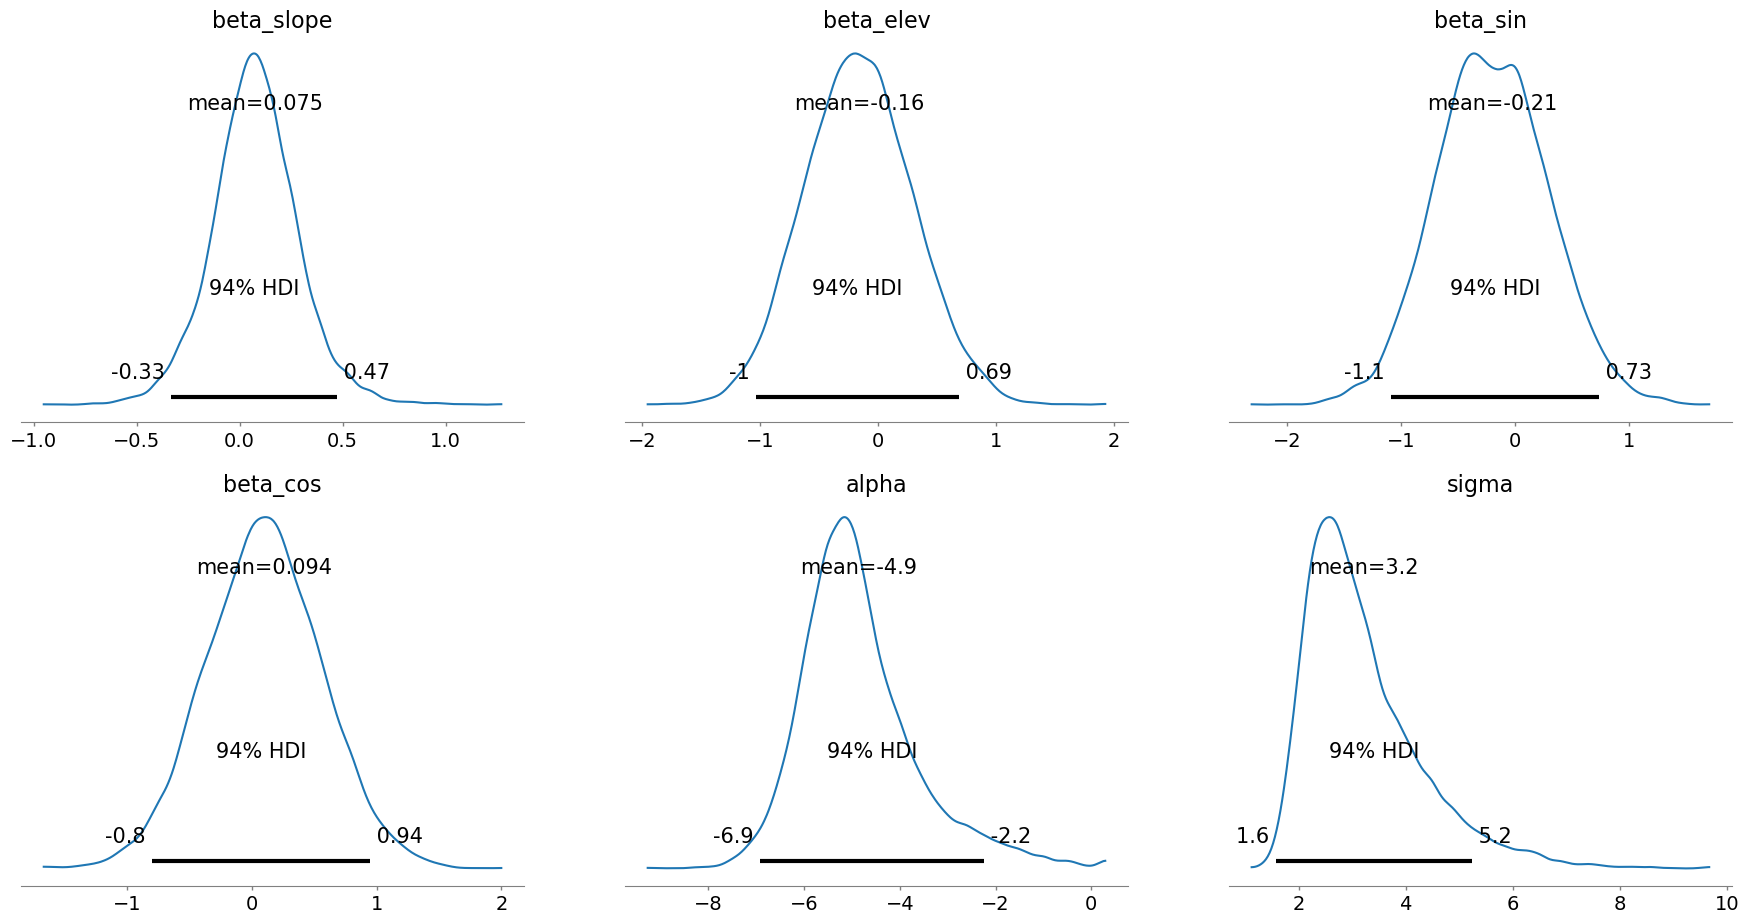

In [35]:
plot_all_posterior_coefficients(model_topography_idata)

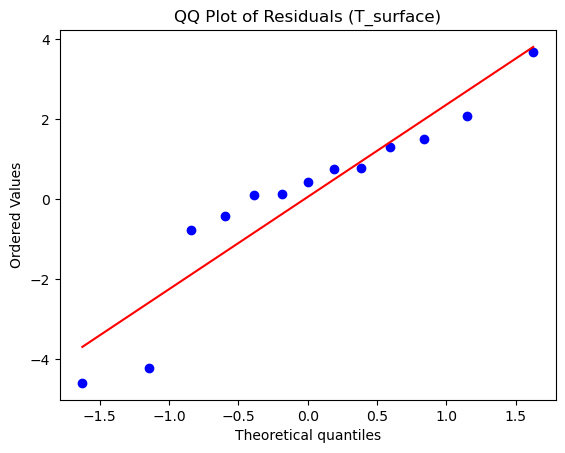

In [36]:
residuals = plot_residual_qq(
    model_topography_idata,
    T_surface,
    var_name="T_surface"
)

In [37]:
r2_table = compute_bayesian_r2(
    model_topography_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.144291,0.099045


In [38]:
loo_topography = compute_loo(model_topography_idata)
print(loo_topography)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -32.50     2.51
p_loo        2.76        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       12   92.3%
   (0.70, 1]   (bad)         1    7.7%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

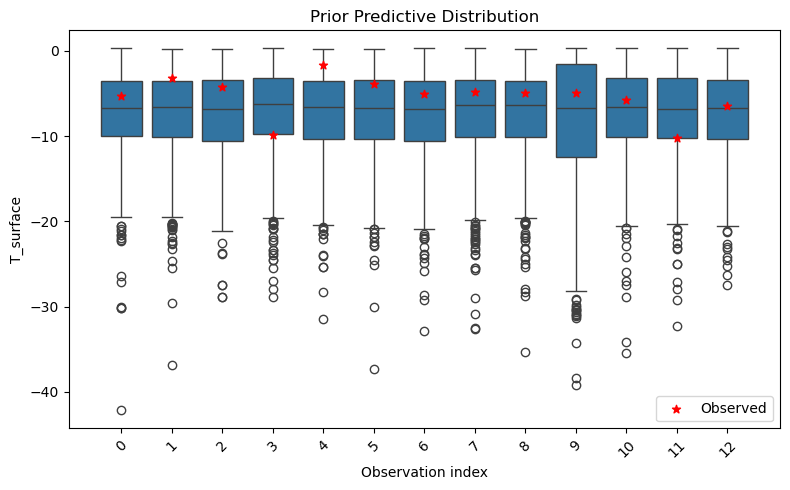

In [39]:
plot_prior_predictions(model_topography_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

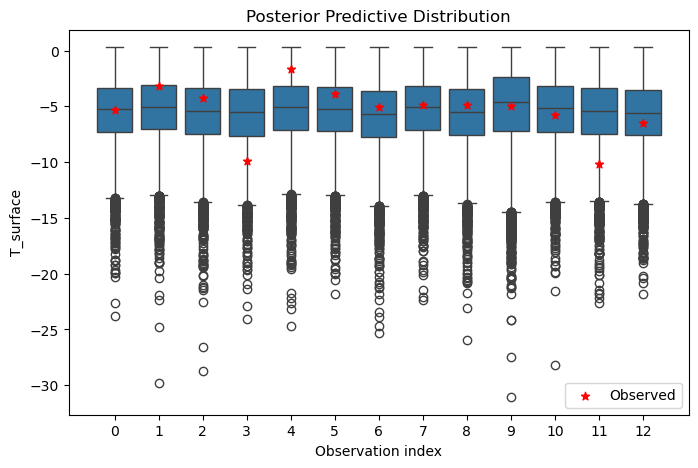

In [40]:
plot_predictions(model_topography_idata)

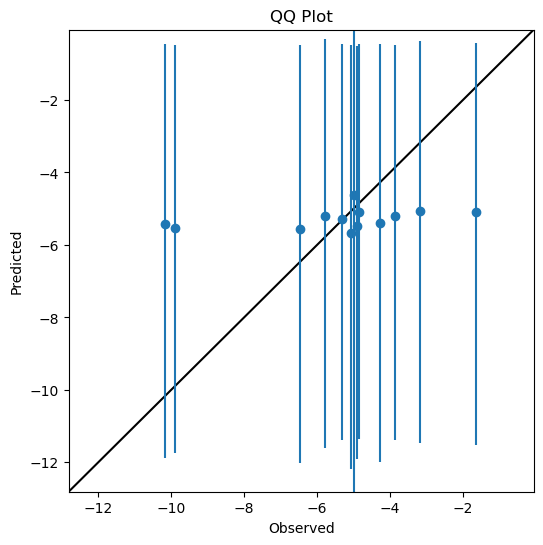

In [41]:
qqplot(model_topography_idata)

## model_density

In [42]:
T_surface = df["T_surface"].values

with pm.Model() as model_density:

    # -------------------------
    # Data
    density = pm.Data("density", df["density_01_c"].values) 


    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-5,  # temperature at mean predictor values, under snow
        sigma=5,
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_density = pm.Normal(
        "beta_density",
        mu=0,        
        sigma=1
    )


    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_density * density
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [43]:
model_density_prior, model_density_idata = run_model(model_density)

Sampling: [T_surface, alpha, beta_density, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_density, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 3 seconds.


There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


Sampling: [T_surface]


Output()

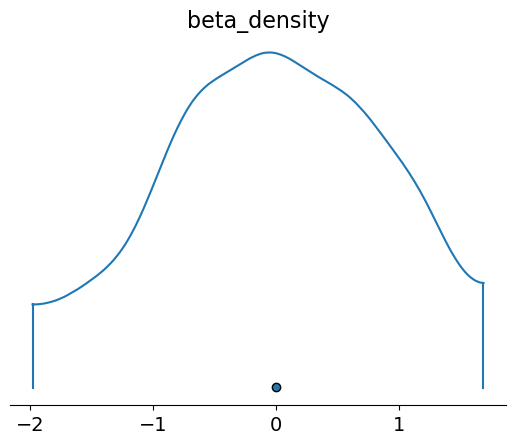

In [44]:
plot_all_prior_coefficients(model_density_prior)

In [45]:
prior_summary = summarize_all_prior_coefficients(model_density_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_density,-0.00,0.98,-1.98,1.69,0.03,0.02,949.33,983.44,NaN
alpha,-6.38,3.99,-13.16,0.30,0.13,0.09,923.07,943.76,NaN


In [46]:
summary = summarize_all_posterior_coefficients(model_density_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_density,-0.13,0.98,-2.03,1.63,0.01,0.01,7458.51,6526.43,1.00
alpha,-5.00,1.11,-6.95,-2.82,0.03,0.04,3366.19,1429.43,1.01
sigma,2.99,0.96,1.56,4.78,0.02,0.02,3651.83,2651.62,1.00


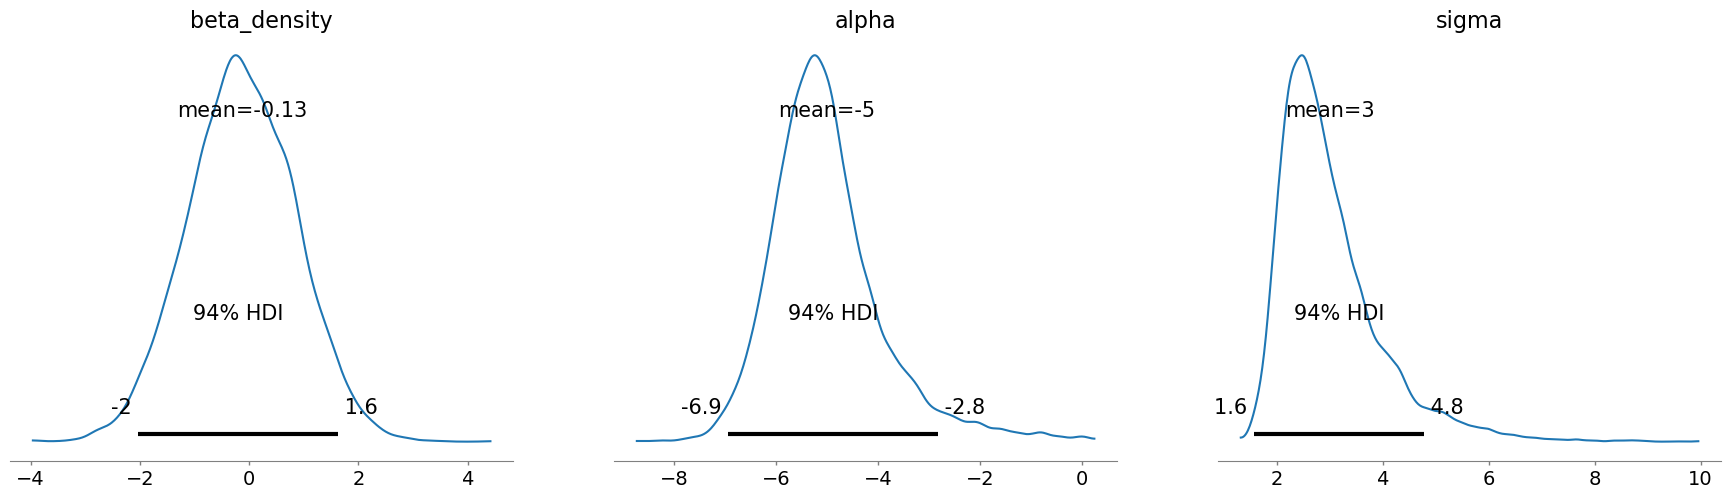

In [47]:
plot_all_posterior_coefficients(model_density_idata)

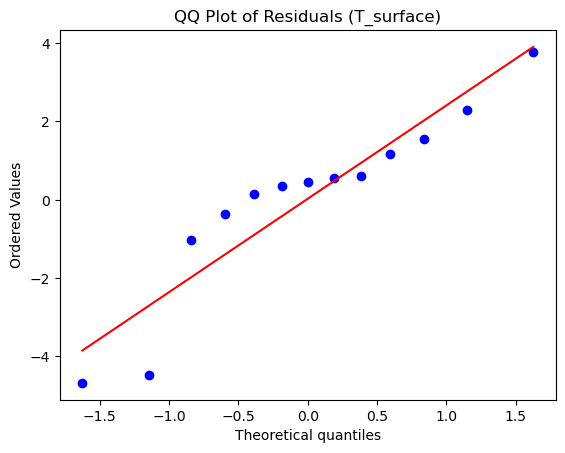

In [48]:
residuals = plot_residual_qq(
    model_density_idata,
    T_surface,
    var_name="T_surface"
)

In [49]:
r2_table = compute_bayesian_r2(
    model_density_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.003502,0.004887


In [50]:
loo_density = compute_loo(model_density_idata)
print(loo_density)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -31.60     2.62
p_loo        2.08        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       13  100.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%



(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

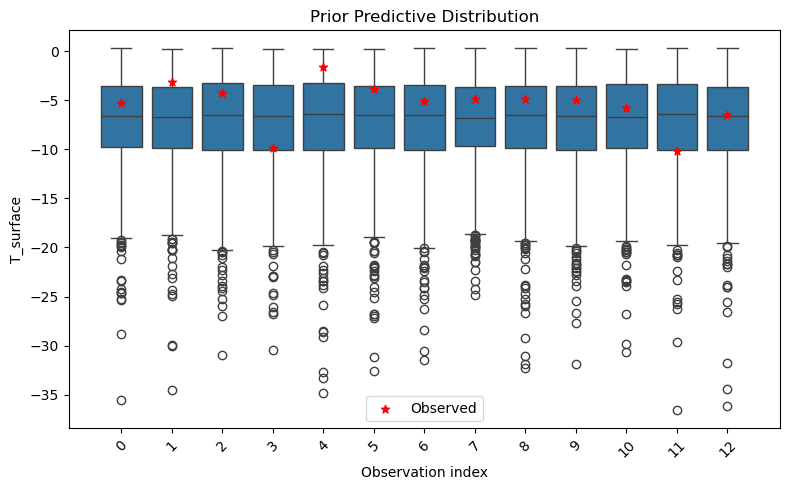

In [51]:
plot_prior_predictions(model_density_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

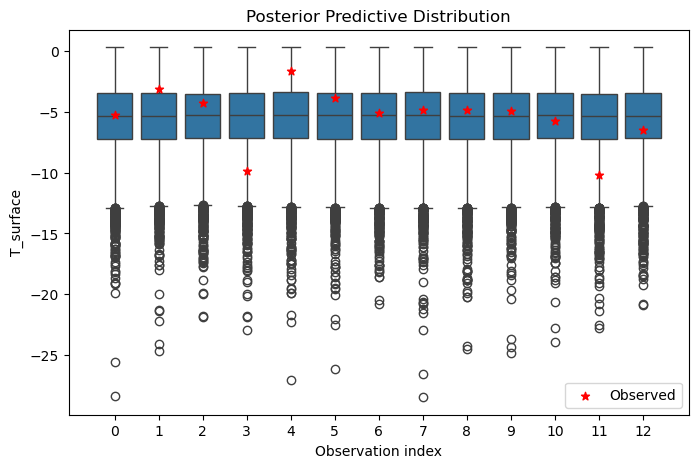

In [52]:
plot_predictions(model_density_idata)

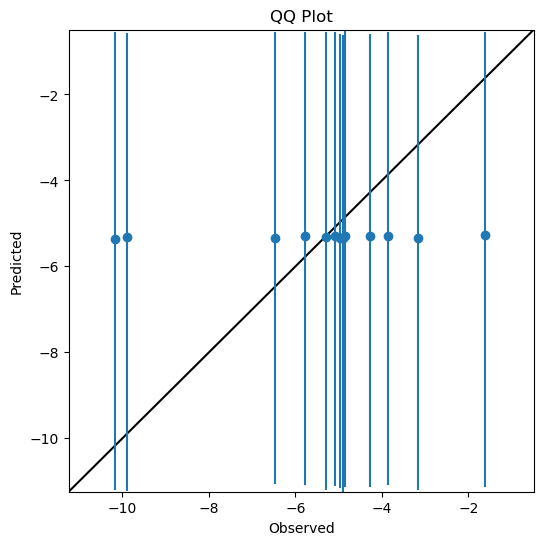

In [53]:
qqplot(model_density_idata)

## model_depth_density

In [54]:
T_surface = df["T_surface"].values

with pm.Model() as model_depth_density:

    # -------------------------
    # Data
    # -------------------------
    snow = pm.Data("snow", df["snow_10cm"].values)       
    density = pm.Data("density", df["density_01_c"].values) 
   
    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,        
        sigma=1.5,      
        upper=0.3       
    )
    
    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,         
        sigma=1
    )

    beta_density = pm.Normal(
        "beta_density",
        mu=0,         
        sigma=1
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_snow * snow
        + beta_density * density
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [55]:
model_depth_density_prior, model_depth_density_idata = run_model(model_depth_density)

Sampling: [T_surface, alpha, beta_density, beta_snow, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma, beta_snow, beta_density]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 5 seconds.


Sampling: [T_surface]


Output()

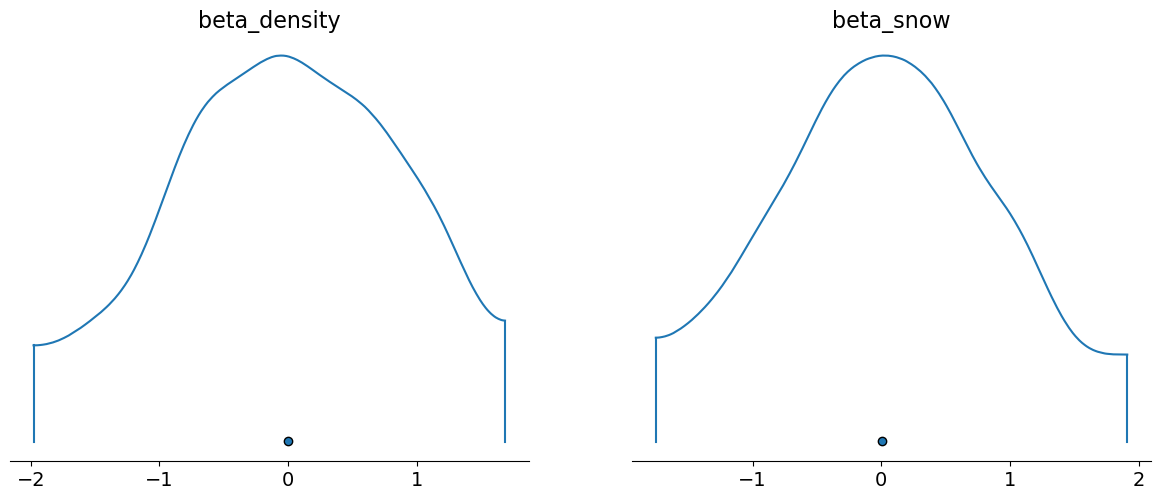

In [56]:
plot_all_prior_coefficients(model_depth_density_prior)

In [57]:
prior_summary = summarize_all_prior_coefficients(model_depth_density_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_density,-0.00,0.98,-1.98,1.69,0.03,0.02,949.33,983.44,NaN
beta_snow,0.00,0.97,-1.75,1.91,0.03,0.02,930.37,930.87,NaN
alpha,-13.23,1.50,-15.98,-10.52,0.05,0.03,793.90,738.30,NaN


In [58]:
summary = summarize_all_posterior_coefficients(model_depth_density_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.26,0.24,0.81,1.71,0.00,0.00,6247.28,6292.22,1.0
beta_density,-0.00,0.95,-1.84,1.73,0.01,0.01,7951.01,6873.92,1.0
alpha,-12.31,1.21,-14.64,-10.13,0.02,0.01,6359.45,6118.54,1.0
sigma,2.08,0.60,1.17,3.14,0.01,0.01,6522.15,5985.90,1.0


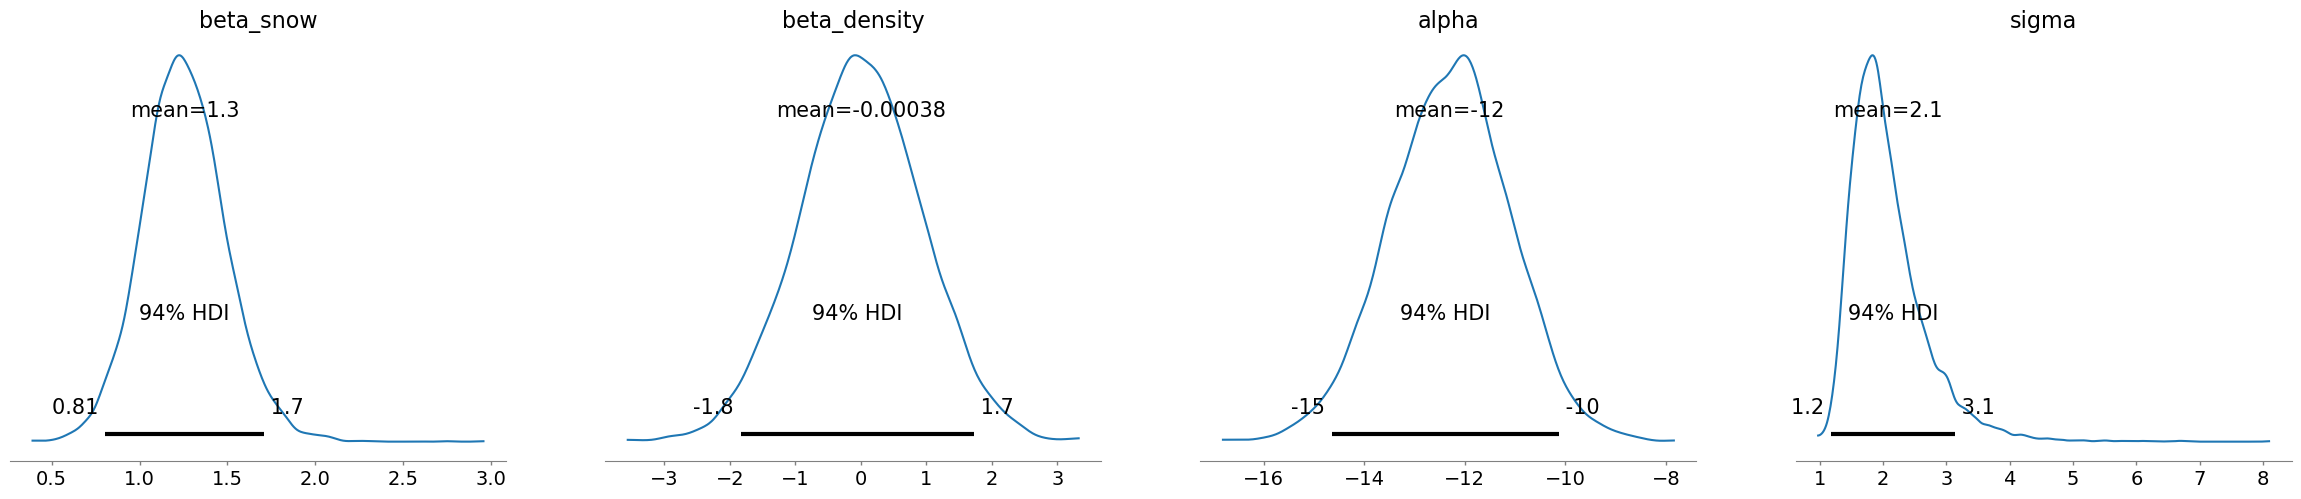

In [59]:
plot_all_posterior_coefficients(model_depth_density_idata)

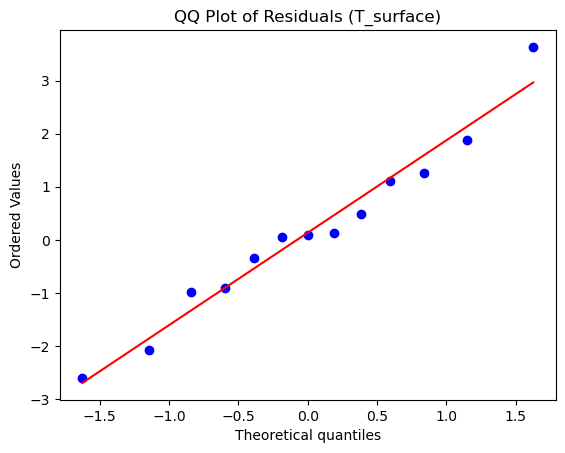

In [60]:
residuals = plot_residual_qq(
    model_depth_density_idata,
    T_surface,
    var_name="T_surface"
)

In [61]:
r2_table = compute_bayesian_r2(
    model_depth_density_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.544785,0.080513


In [62]:
loo_depth_density = compute_loo(model_depth_density_idata)
print(loo_depth_density)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -27.83     2.52
p_loo        2.42        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       12   92.3%
   (0.70, 1]   (bad)         1    7.7%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

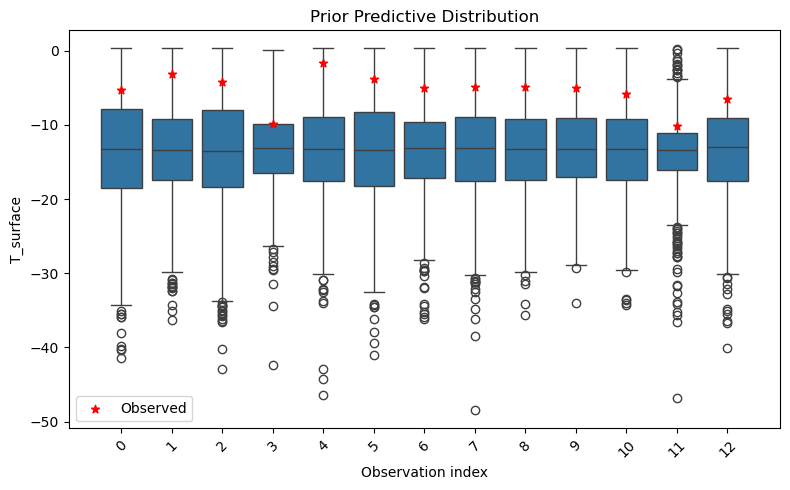

In [63]:
plot_prior_predictions(model_depth_density_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

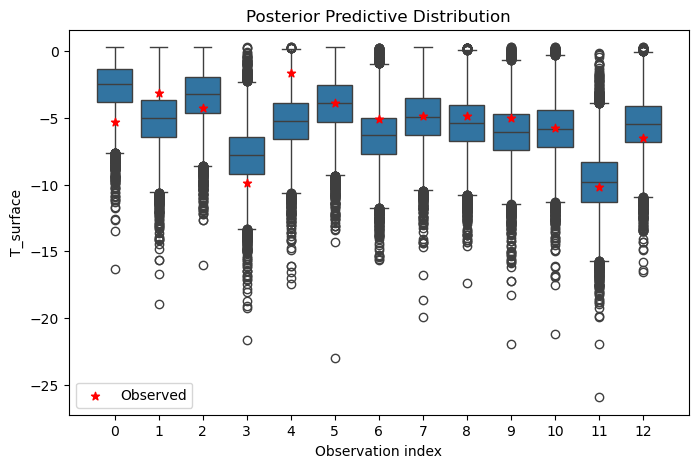

In [64]:
plot_predictions(model_depth_density_idata)

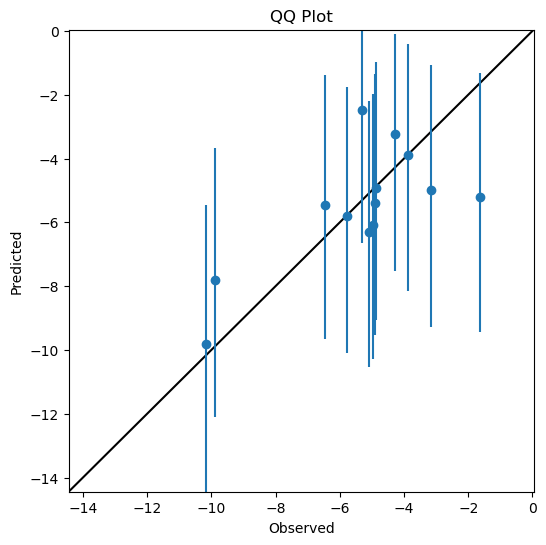

In [65]:
qqplot(model_depth_density_idata)

## model_depth_topography

In [66]:
T_surface = df["T_surface"].values

with pm.Model() as model_depth_topography:

    # -------------------------
    # Data
    # -------------------------
    snow = pm.Data("snow", df["snow_10cm"].values)      
    slope = pm.Data("slope", df["slope_c"].values)
    elev = pm.Data("elev", df["elev_10m_c"].values)
    asp_sin = pm.Data("asp_sin", df["aspect_sin_c"].values)
    asp_cos = pm.Data("asp_cos", df["aspect_cos_c"].values)

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,        
        sigma=1.5,      
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,         
        sigma=1
    )

    beta_slope = pm.Normal(
        "beta_slope",
        mu=0.0,         
        sigma=0.5       
    )

    beta_elev = pm.Normal(
        "beta_elev",
        mu=0.0,
        sigma=0.5
    )

    beta_sin = pm.Normal(
        "beta_sin",
        mu=0.0,
        sigma=0.5
    )

    beta_cos = pm.Normal(
        "beta_cos",
        mu=0.0,
        sigma=0.5
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4  
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_snow * snow
        + beta_slope * slope
        + beta_elev * elev
        + beta_sin * asp_sin
        + beta_cos * asp_cos
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [67]:
model_depth_topography_prior, model_depth_topography_idata = run_model(model_depth_topography)

Sampling: [T_surface, alpha, beta_cos, beta_elev, beta_sin, beta_slope, beta_snow, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_snow, beta_slope, beta_elev, beta_sin, beta_cos, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 6 seconds.


Sampling: [T_surface]


Output()

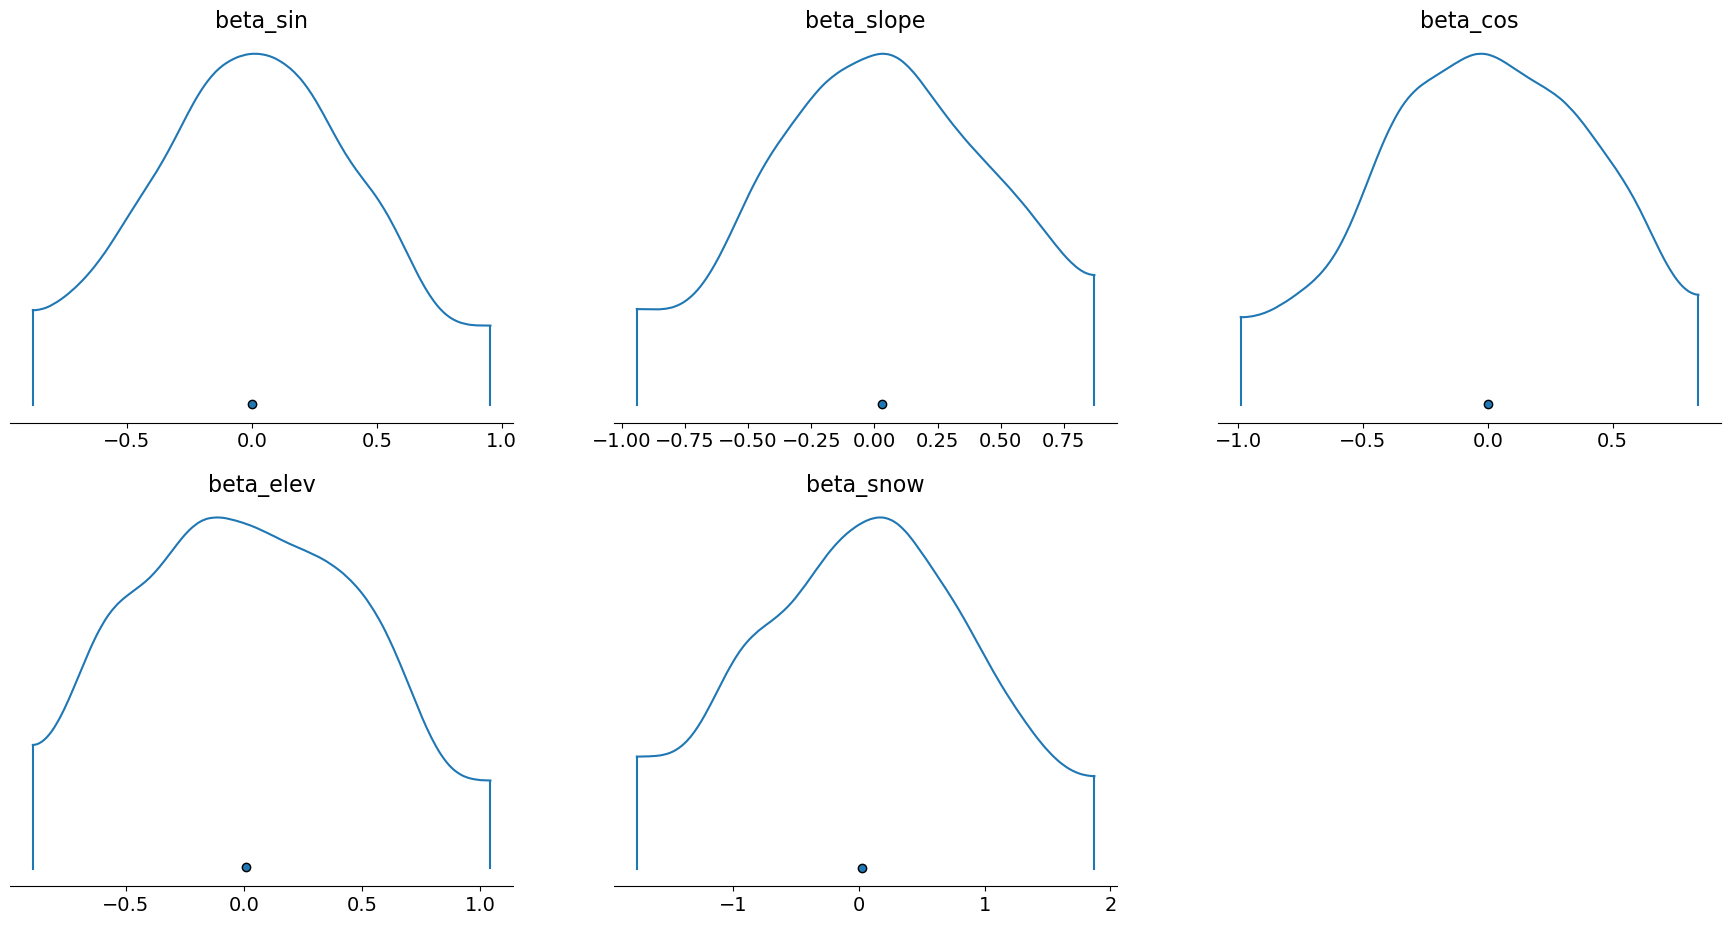

In [68]:
plot_all_prior_coefficients(model_depth_topography_prior)

In [69]:
prior_summary = summarize_all_prior_coefficients(model_depth_topography_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_sin,0.00,0.49,-0.88,0.96,0.02,0.01,930.37,930.87,NaN
beta_slope,0.03,0.50,-0.94,0.87,0.02,0.01,1008.75,982.80,NaN
beta_cos,-0.00,0.49,-0.99,0.85,0.02,0.01,949.33,983.44,NaN
beta_elev,0.01,0.53,-0.90,1.05,0.02,0.01,1020.11,778.10,NaN
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_snow,0.02,0.99,-1.77,1.88,0.03,0.02,872.25,914.55,NaN
alpha,-13.30,1.49,-15.94,-10.36,0.05,0.03,1051.84,983.44,NaN


In [70]:
summary = summarize_all_posterior_coefficients(model_depth_topography_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.27,0.25,0.79,1.74,0.00,0.00,7641.38,7253.32,1.0
beta_slope,0.09,0.15,-0.20,0.35,0.00,0.00,8345.22,7419.88,1.0
beta_elev,-0.17,0.43,-0.99,0.61,0.00,0.00,11173.40,8533.17,1.0
beta_sin,-0.15,0.47,-1.00,0.77,0.00,0.00,9886.37,7586.04,1.0
beta_cos,0.06,0.45,-0.79,0.86,0.00,0.00,11699.78,8413.07,1.0
alpha,-12.31,1.23,-14.70,-10.06,0.01,0.01,8293.77,7517.18,1.0
sigma,2.21,0.71,1.17,3.49,0.01,0.01,6504.87,6142.79,1.0


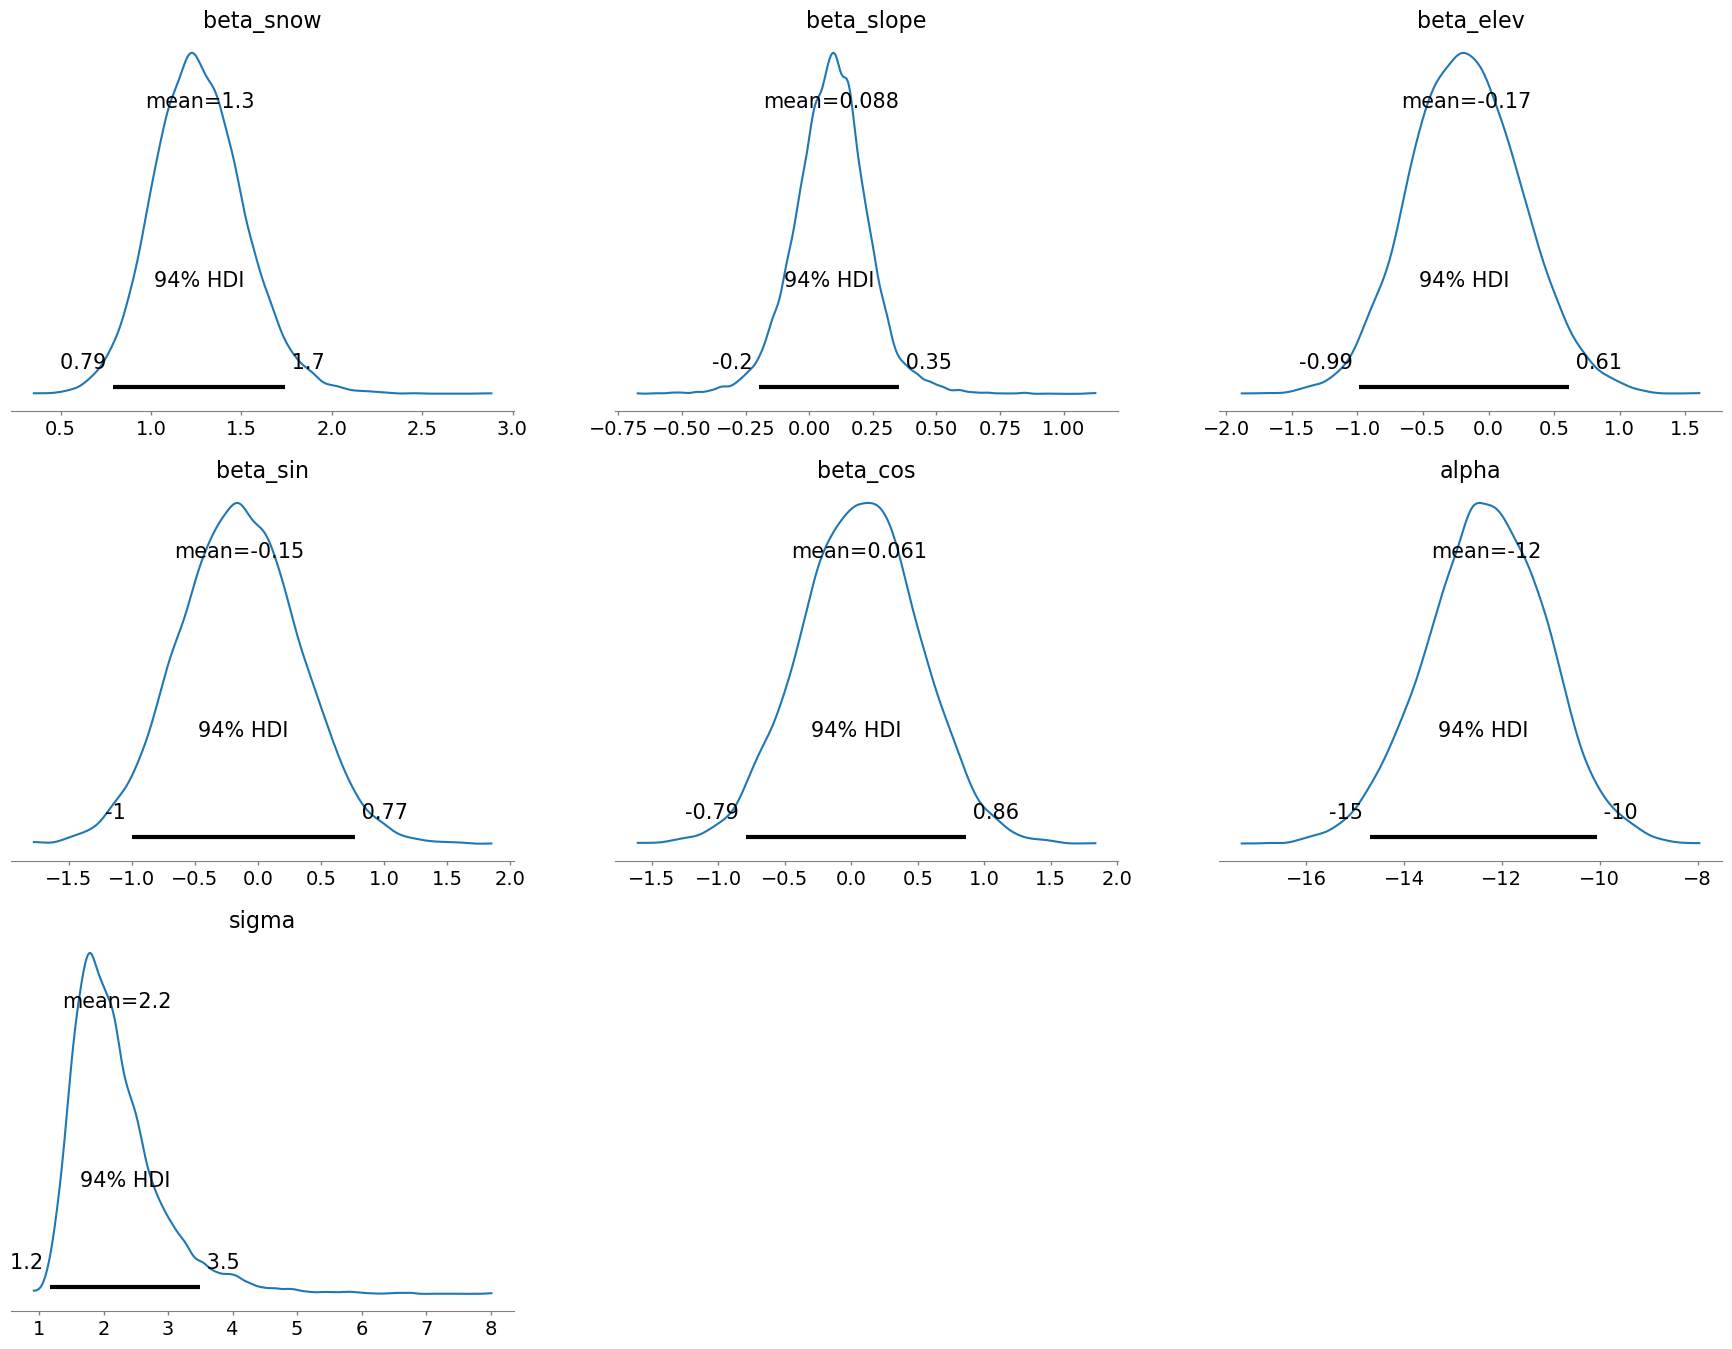

In [71]:
plot_all_posterior_coefficients(model_depth_topography_idata)

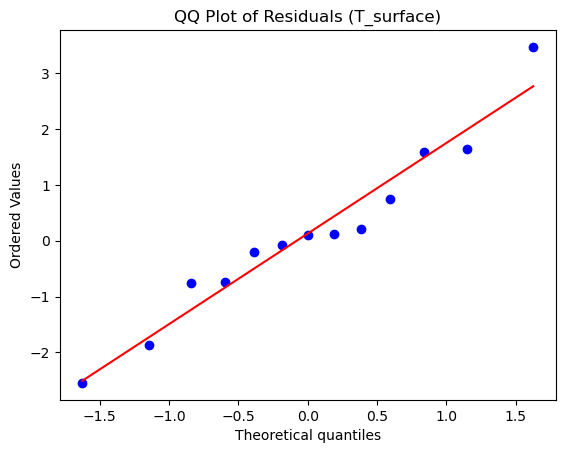

In [72]:
residuals = plot_residual_qq(
    model_depth_topography_idata,
    T_surface,
    var_name="T_surface"
)

In [73]:
r2_table = compute_bayesian_r2(
    model_depth_topography_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.575135,0.077101


In [74]:
loo_depth_topography = compute_loo(model_depth_topography_idata)
print(loo_depth_topography)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -28.98     2.25
p_loo        3.33        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       11   84.6%
   (0.70, 1]   (bad)         2   15.4%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

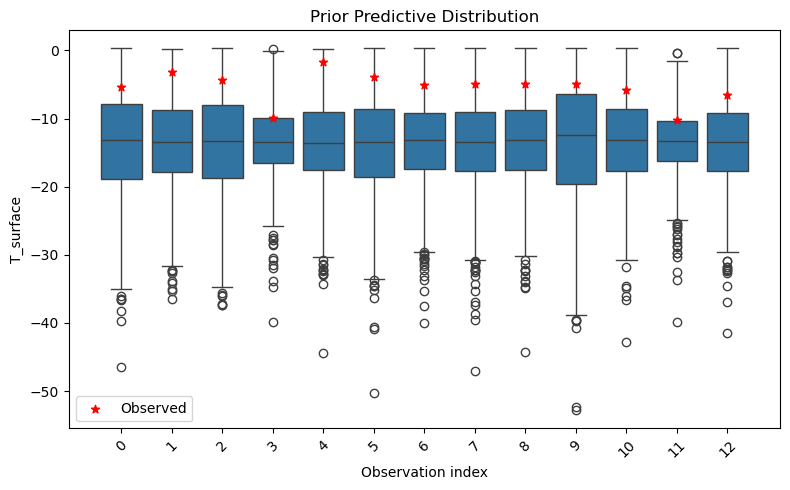

In [75]:
plot_prior_predictions(model_depth_topography_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

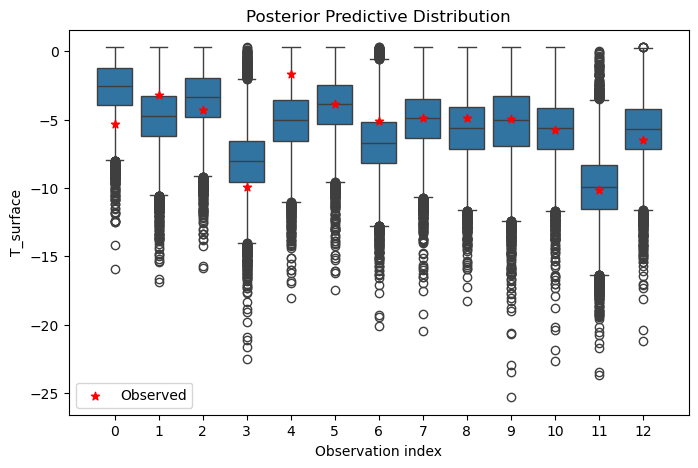

In [76]:
plot_predictions(model_depth_topography_idata)

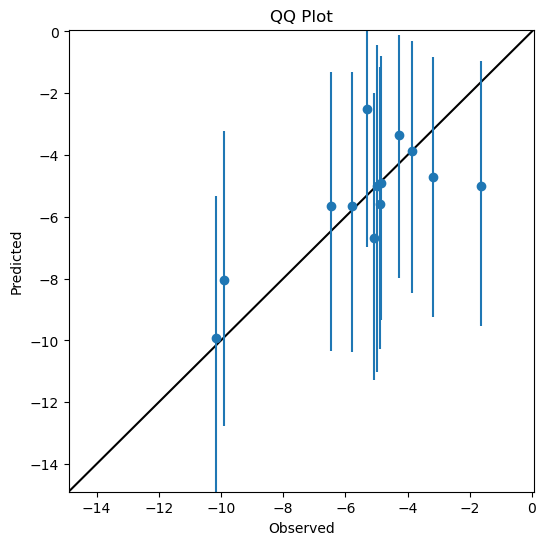

In [77]:
qqplot(model_depth_topography_idata)

## model_density_topography

In [78]:
T_surface = df["T_surface"].values

with pm.Model() as model_density_topography:

    # -------------------------
    # Data
    # -------------------------
    density = pm.Data("density", df["density_01_c"].values) 
    slope = pm.Data("slope", df["slope_c"].values)
    elev = pm.Data("elev", df["elev_10m_c"].values)
    asp_sin = pm.Data("asp_sin", df["aspect_sin_c"].values)
    asp_cos = pm.Data("asp_cos", df["aspect_cos_c"].values)

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-5,  # temperature at mean predictor values, under snow
        sigma=5,
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_density = pm.Normal(
        "beta_density",
        mu=0,        
        sigma=1
    )

    beta_slope = pm.Normal(
        "beta_slope",
        mu=0.0,         
        sigma=0.5       
    )

    beta_elev = pm.Normal(
        "beta_elev",
        mu=0.0,
        sigma=0.5
    )

    beta_sin = pm.Normal(
        "beta_sin",
        mu=0.0,
        sigma=0.5
    )

    beta_cos = pm.Normal(
        "beta_cos",
        mu=0.0,
        sigma=0.5
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_density * density
        + beta_slope * slope
        + beta_elev * elev
        + beta_sin * asp_sin
        + beta_cos * asp_cos
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [79]:
model_density_topography_prior, model_density_topography_idata = run_model(model_density_topography)

Sampling: [T_surface, alpha, beta_cos, beta_density, beta_elev, beta_sin, beta_slope, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_density, beta_slope, beta_elev, beta_sin, beta_cos, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 5 seconds.


Sampling: [T_surface]


Output()

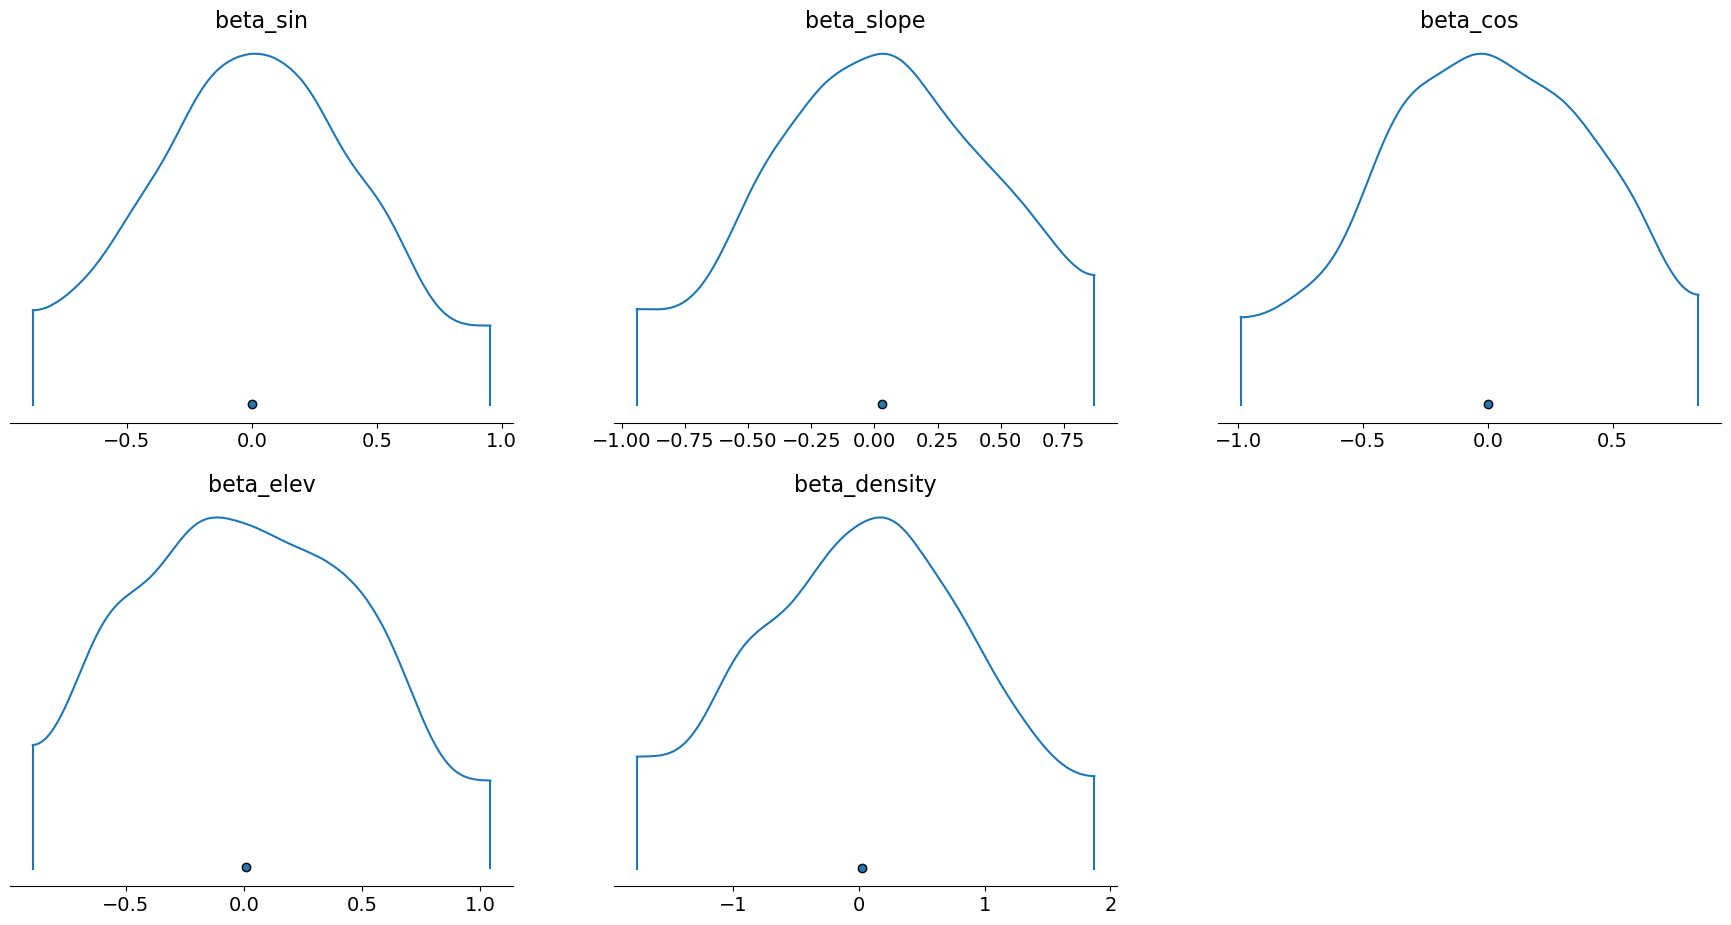

In [80]:
plot_all_prior_coefficients(model_density_topography_prior)

In [81]:
prior_summary = summarize_all_prior_coefficients(model_density_topography_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_sin,0.00,0.49,-0.88,0.96,0.02,0.01,930.37,930.87,NaN
beta_slope,0.03,0.50,-0.94,0.87,0.02,0.01,1008.75,982.80,NaN
beta_cos,-0.00,0.49,-0.99,0.85,0.02,0.01,949.33,983.44,NaN
beta_elev,0.01,0.53,-0.90,1.05,0.02,0.01,1020.11,778.10,NaN
beta_density,0.02,0.99,-1.77,1.88,0.03,0.02,872.25,914.55,NaN
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
alpha,-6.60,3.98,-13.07,0.30,0.12,0.08,1051.84,983.44,NaN


In [82]:
summary = summarize_all_posterior_coefficients(model_density_topography_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_density,-0.11,0.99,-2.01,1.71,0.01,0.01,14733.87,8571.60,1.0
beta_slope,0.08,0.21,-0.34,0.47,0.00,0.00,8862.20,6663.38,1.0
beta_elev,-0.16,0.46,-1.05,0.69,0.00,0.00,11835.29,8791.59,1.0
beta_sin,-0.20,0.49,-1.08,0.78,0.00,0.00,13125.92,8218.32,1.0
beta_cos,0.09,0.48,-0.86,0.94,0.00,0.00,13539.20,8379.52,1.0
alpha,-4.85,1.21,-6.87,-2.32,0.02,0.03,4149.10,1925.96,1.0
sigma,3.20,1.05,1.65,5.22,0.02,0.02,4243.04,4408.99,1.0


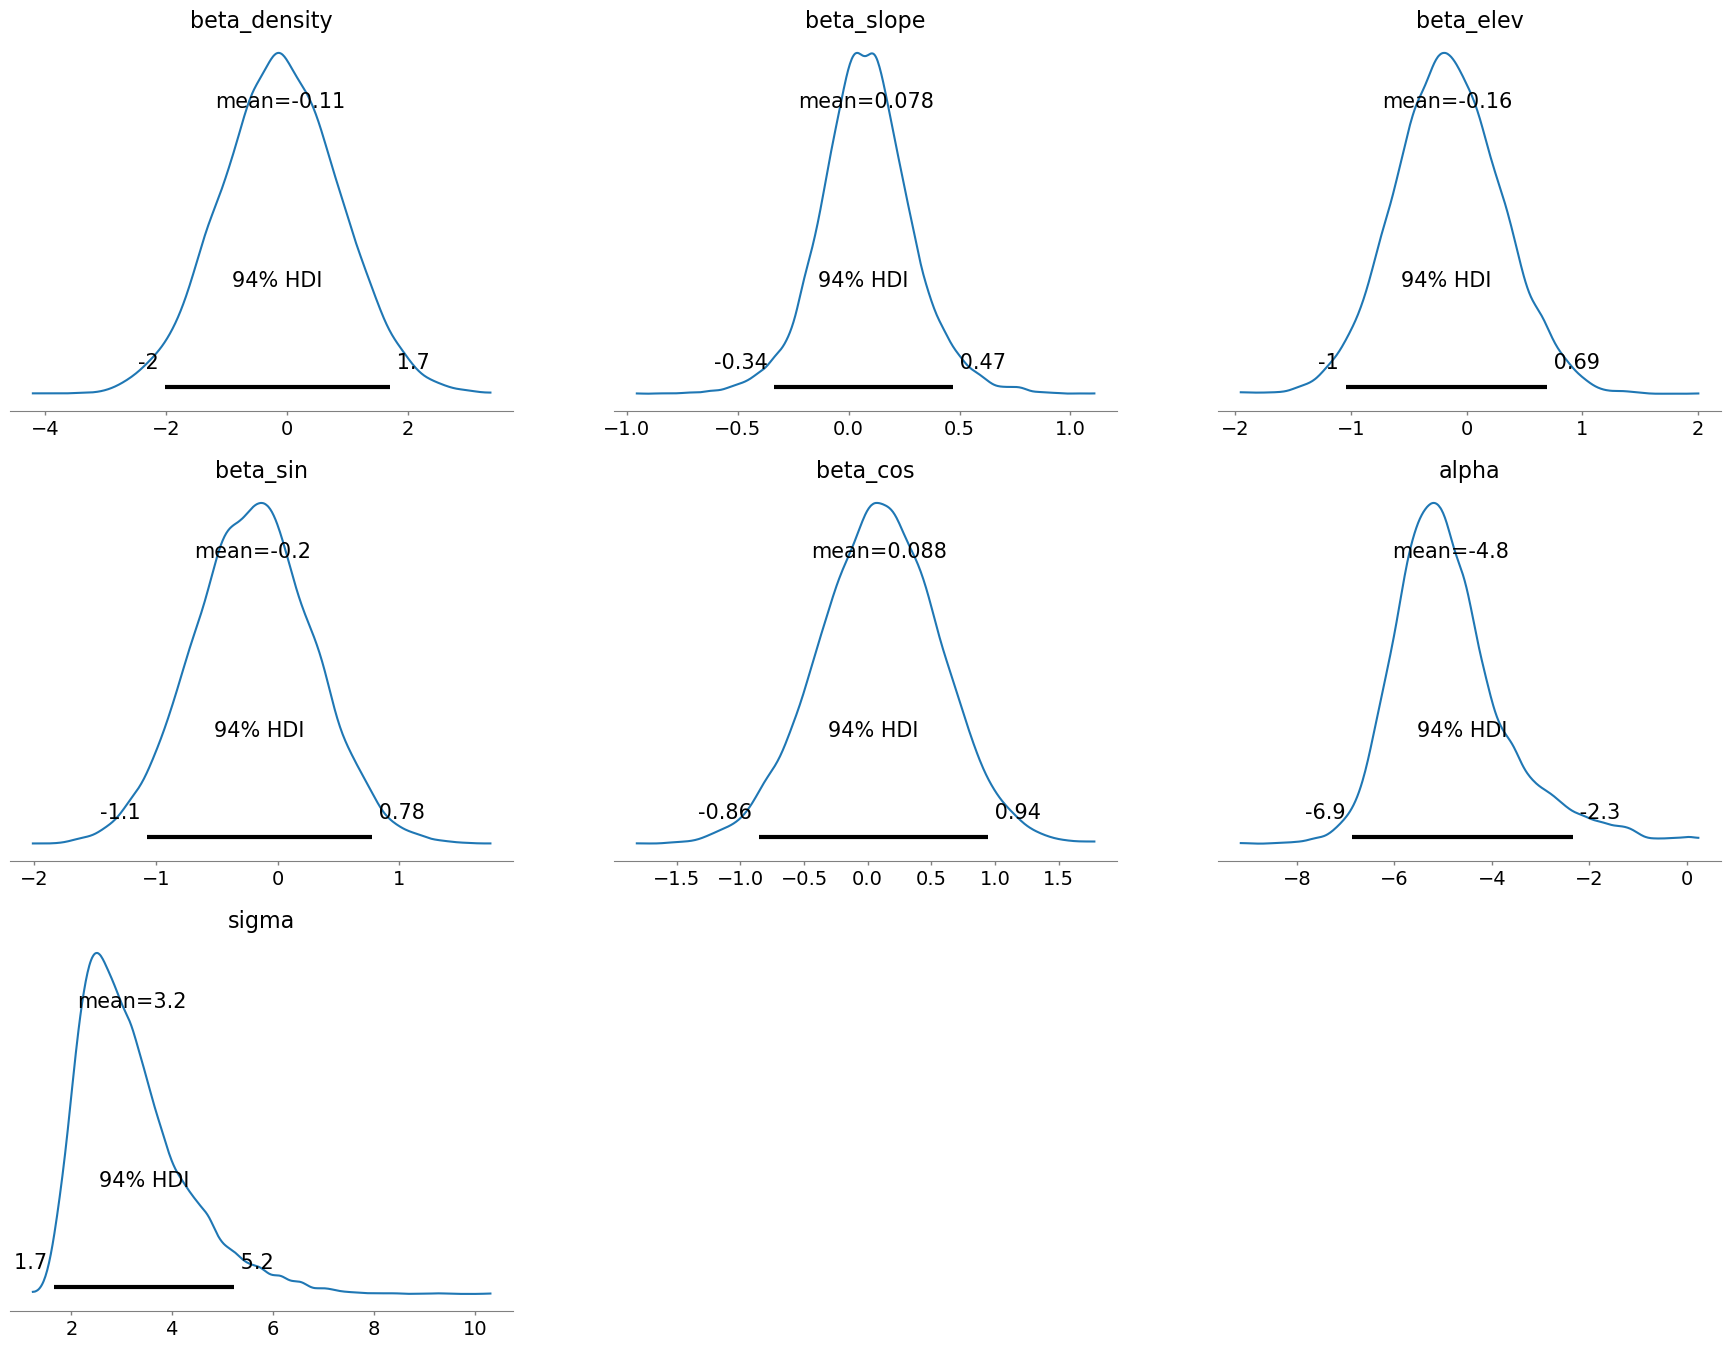

In [83]:
plot_all_posterior_coefficients(model_density_topography_idata)

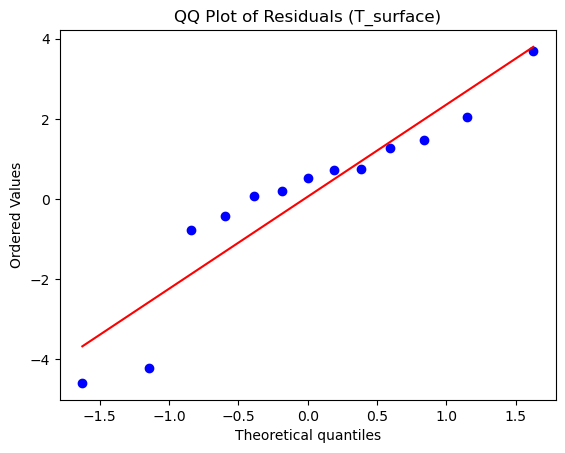

In [84]:
residuals = plot_residual_qq(
    model_density_topography_idata,
    T_surface,
    var_name="T_surface"
)

In [85]:
r2_table = compute_bayesian_r2(
    model_density_topography_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.147249,0.100627


In [86]:
loo_density_topography = compute_loo(model_density_topography_idata)
print(loo_density_topography)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -32.54     2.50
p_loo        2.82        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       10   76.9%
   (0.70, 1]   (bad)         3   23.1%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

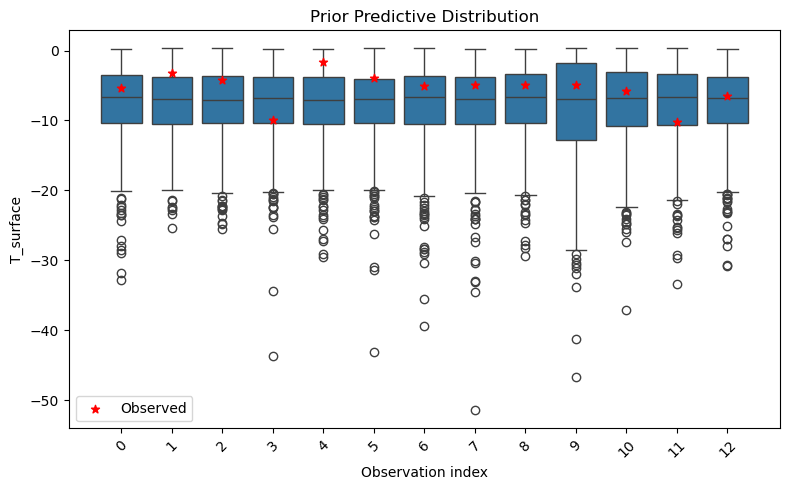

In [87]:
plot_prior_predictions(model_density_topography_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

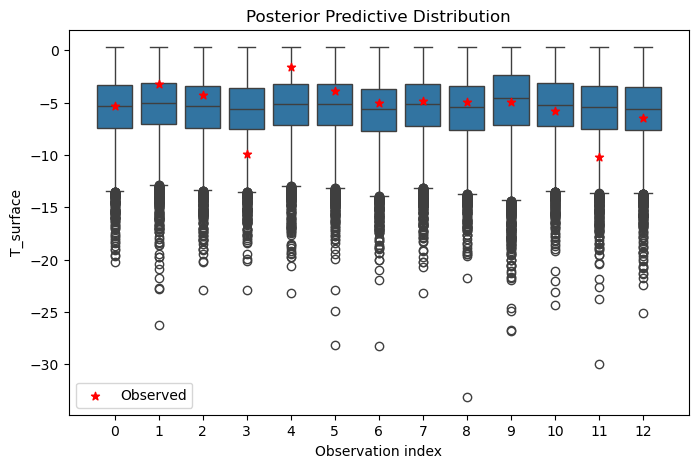

In [88]:
plot_predictions(model_density_topography_idata)

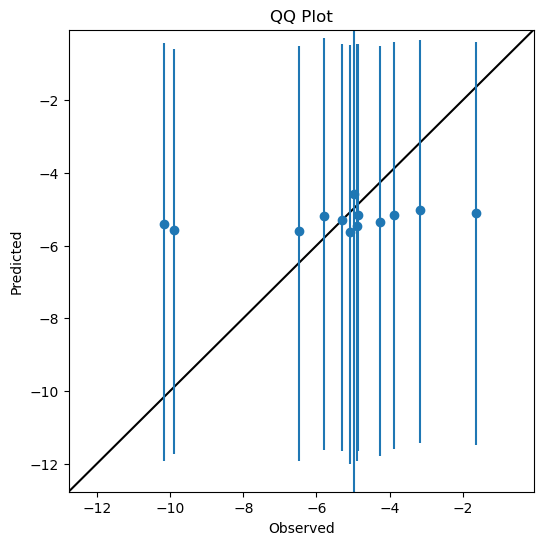

In [89]:
qqplot(model_density_topography_idata)

## model_depth_density_topography

In [90]:
T_surface = df["T_surface"].values

with pm.Model() as model_depth_density_topography:

    # -------------------------
    # Data
    # -------------------------
    snow = pm.Data("snow", df["snow_10cm"].values)      
    density = pm.Data("density", df["density_01_c"].values) 
    slope = pm.Data("slope", df["slope_c"].values)
    elev = pm.Data("elev", df["elev_10m_c"].values)
    asp_sin = pm.Data("asp_sin", df["aspect_sin_c"].values)
    asp_cos = pm.Data("asp_cos", df["aspect_cos_c"].values)

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,        
        sigma=1.5,      
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,        
        sigma=1
    )

    beta_density = pm.Normal(
        "beta_density",
        mu=0,         
        sigma=1
    )

    beta_slope = pm.Normal(
        "beta_slope",
        mu=0.0,         
        sigma=0.5       
    )

    beta_elev = pm.Normal(
        "beta_elev",
        mu=0.0,
        sigma=0.5
    )

    beta_sin = pm.Normal(
        "beta_sin",
        mu=0.0,
        sigma=0.5
    )

    beta_cos = pm.Normal(
        "beta_cos",
        mu=0.0,
        sigma=0.5
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_snow * snow
        + beta_density * density
        + beta_slope * slope
        + beta_elev * elev
        + beta_sin * asp_sin
        + beta_cos * asp_cos
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [91]:
model_depth_density_topography_prior, model_depth_density_topography_idata = run_model(model_depth_density_topography)

Sampling: [T_surface, alpha, beta_cos, beta_density, beta_elev, beta_sin, beta_slope, beta_snow, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_snow, beta_density, beta_slope, beta_elev, beta_sin, beta_cos, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 7 seconds.


Sampling: [T_surface]


Output()

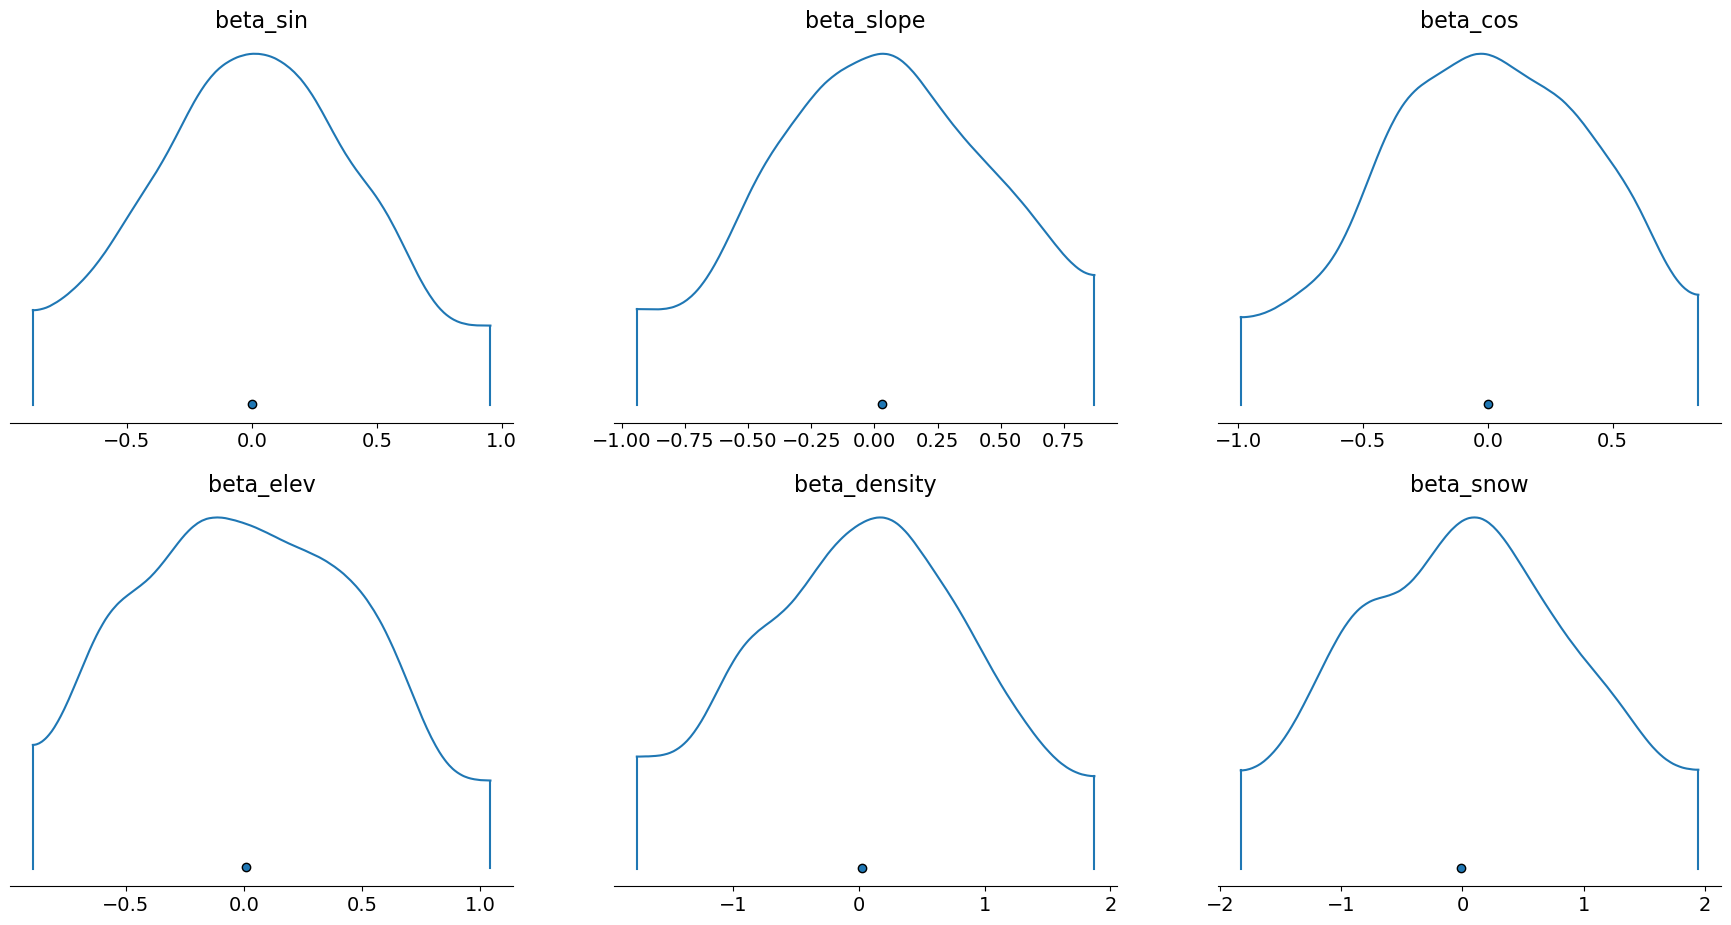

In [92]:
plot_all_prior_coefficients(model_depth_density_topography_prior)

In [93]:
prior_summary = summarize_all_prior_coefficients(model_depth_density_topography_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_sin,0.00,0.49,-0.88,0.96,0.02,0.01,930.37,930.87,NaN
beta_slope,0.03,0.50,-0.94,0.87,0.02,0.01,1008.75,982.80,NaN
beta_cos,-0.00,0.49,-0.99,0.85,0.02,0.01,949.33,983.44,NaN
beta_elev,0.01,0.53,-0.90,1.05,0.02,0.01,1020.11,778.10,NaN
beta_density,0.02,0.99,-1.77,1.88,0.03,0.02,872.25,914.55,NaN
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_snow,-0.01,1.02,-1.83,1.95,0.04,0.02,825.98,880.24,NaN
alpha,-13.22,1.48,-15.92,-10.59,0.05,0.03,962.28,891.50,NaN


In [94]:
summary = summarize_all_posterior_coefficients(model_depth_density_topography_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.26,0.26,0.80,1.76,0.00,0.00,7385.29,7349.07,1.0
beta_density,-0.04,0.98,-1.84,1.82,0.01,0.01,13857.33,8584.51,1.0
beta_slope,0.09,0.15,-0.20,0.36,0.00,0.00,9801.74,6291.58,1.0
beta_elev,-0.17,0.43,-0.94,0.66,0.00,0.00,12927.87,8604.12,1.0
beta_sin,-0.15,0.46,-1.00,0.73,0.00,0.00,13557.82,8883.29,1.0
beta_cos,0.07,0.44,-0.76,0.90,0.00,0.00,14227.19,8433.69,1.0
alpha,-12.29,1.24,-14.71,-10.02,0.01,0.01,8527.65,8853.37,1.0
sigma,2.21,0.73,1.16,3.53,0.01,0.01,6416.56,5929.06,1.0


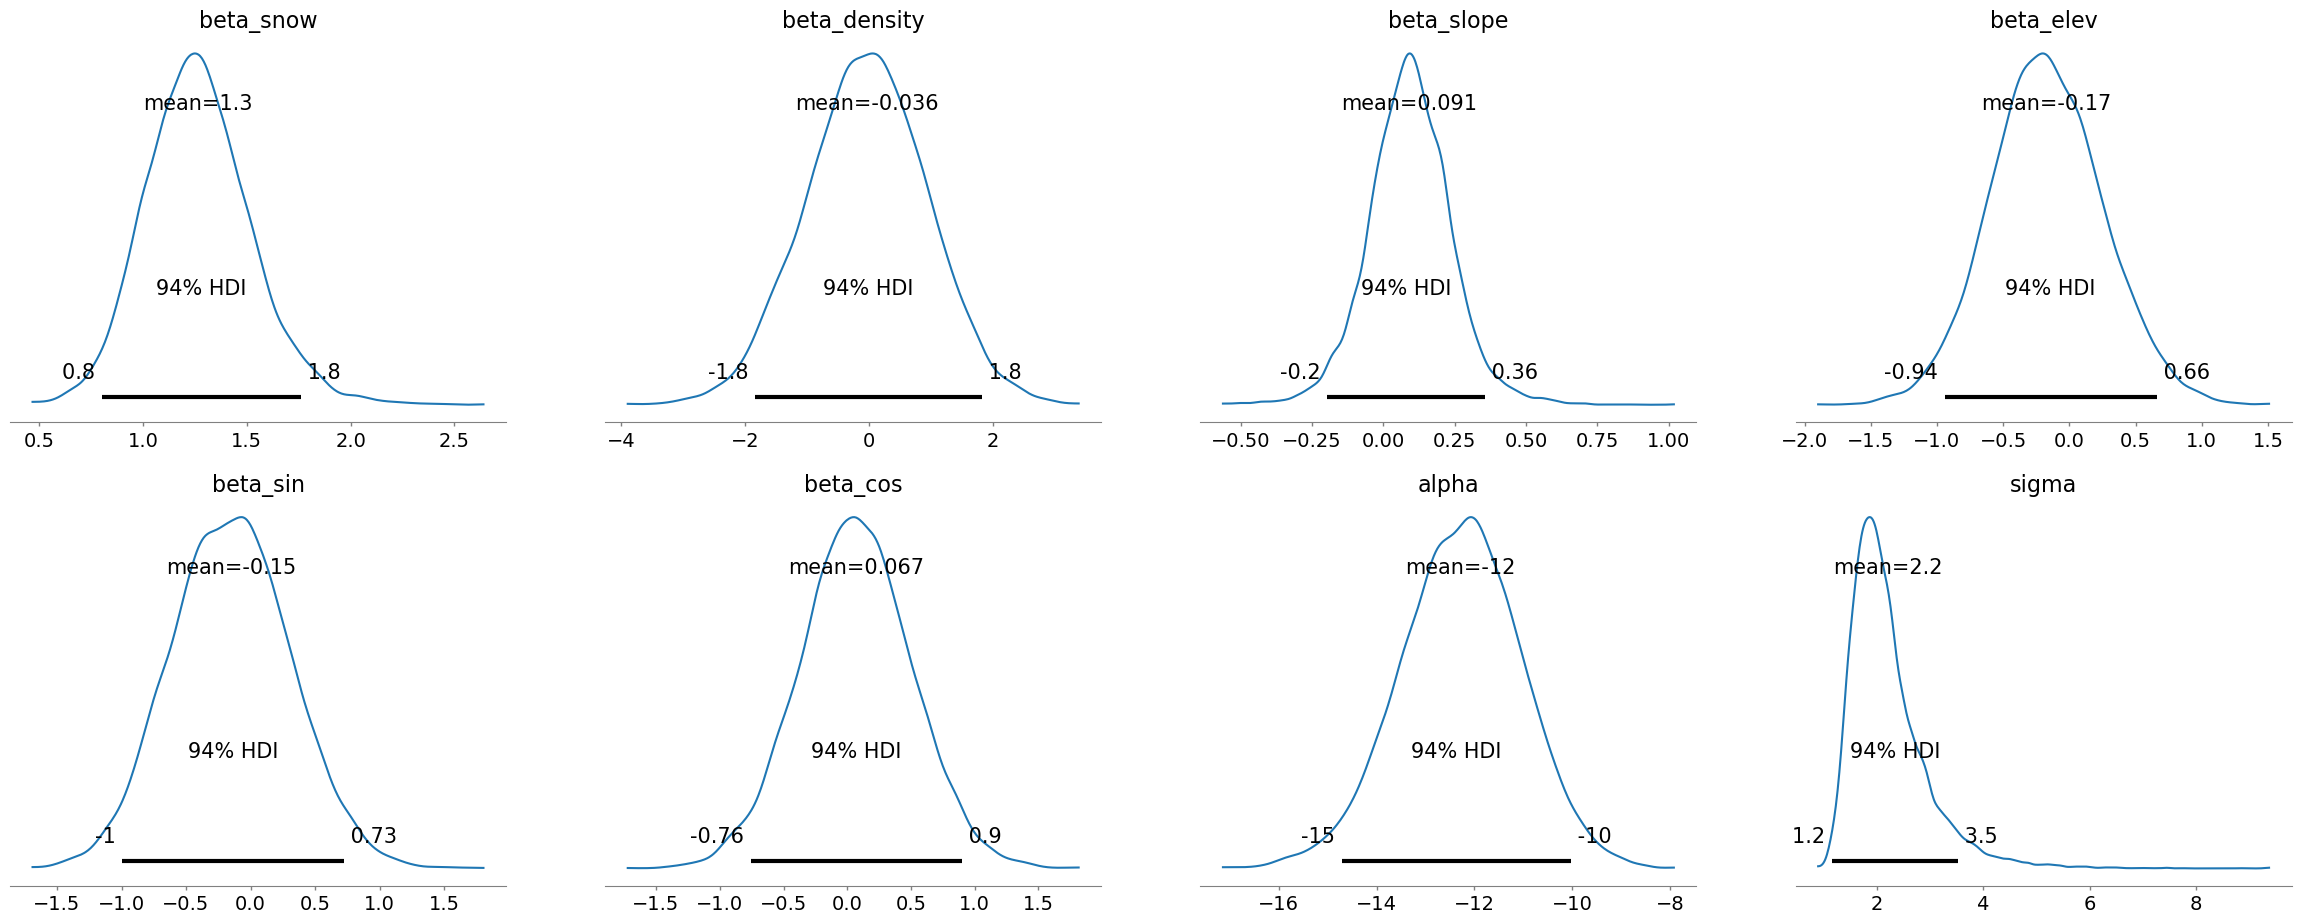

In [95]:
plot_all_posterior_coefficients(model_depth_density_topography_idata)

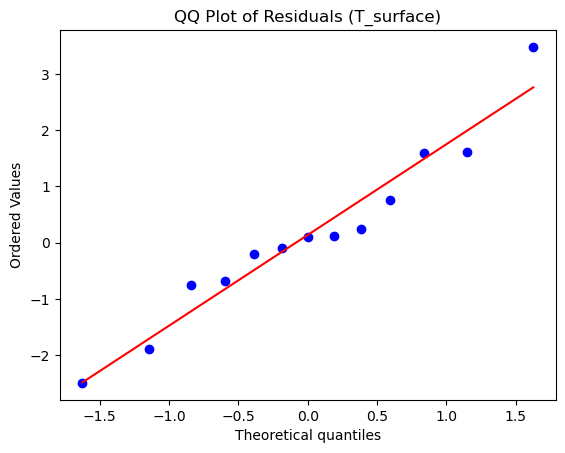

In [96]:
residuals = plot_residual_qq(
    model_depth_density_topography_idata,
    T_surface,
    var_name="T_surface"
)

In [97]:
r2_table = compute_bayesian_r2(
    model_depth_density_topography_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.575053,0.076923


In [98]:
loo_depth_density_topography = compute_loo(model_depth_density_topography_idata)
print(loo_depth_density_topography)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -28.96     2.26
p_loo        3.30        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       11   84.6%
   (0.70, 1]   (bad)         2   15.4%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

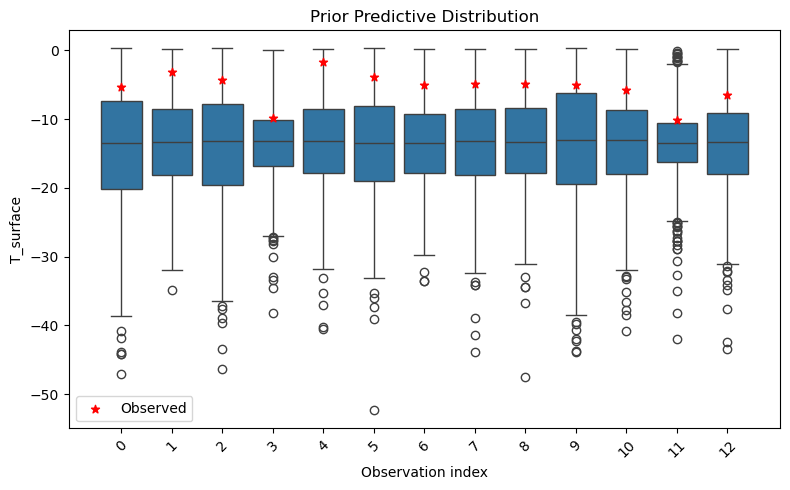

In [99]:
plot_prior_predictions(model_depth_density_topography_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

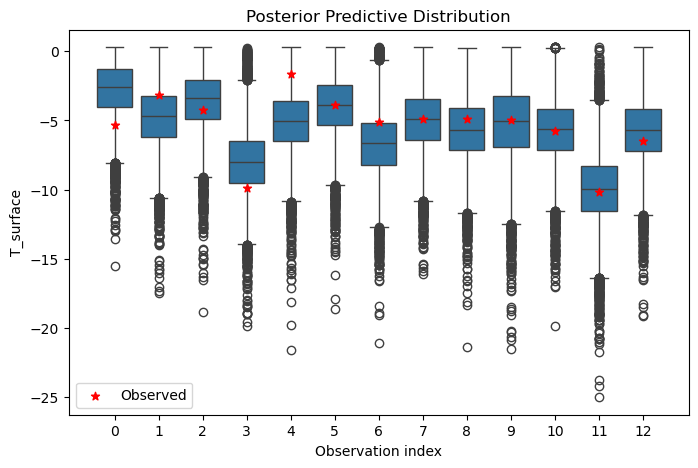

In [100]:
plot_predictions(model_depth_density_topography_idata)

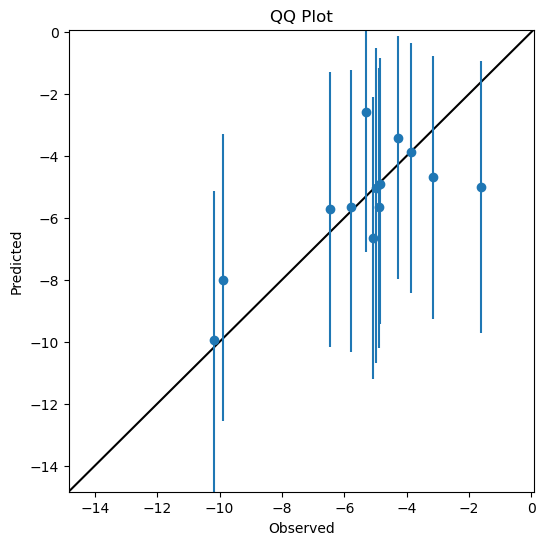

In [101]:
qqplot(model_depth_density_topography_idata)

In [102]:
models = {
    "depth": model_depth_idata,
    "density": model_density_idata,
    "depth_density": model_depth_density_idata,
    "depth_topography": model_depth_topography_idata,
    "density_topography": model_density_topography_idata,
    "depth_density_topography": model_depth_density_topography_idata,
    "topography": model_topography_idata
}



In [103]:
comparison_results = []

for name, idata in models.items():
    
    # R²
    r2 = compute_bayesian_r2(idata, T_surface)
    r2_mean = float(r2["R2_mean"].values[0])
    r2_sd   = float(r2["R2_sd"].values[0])
    
    # LOO
    loo = compute_loo(idata)
    
    comparison_results.append({
        "Model": name,
        "R2_mean": r2_mean,
        "R2_sd": r2_sd,
        "elpd_loo": loo.elpd_loo,
        "p_loo": loo.p_loo,
        "loo_se": loo.se
    })

comparison_table = pd.DataFrame(comparison_results)


/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/py

In [104]:
print(comparison_table)

                      Model   R2_mean     R2_sd   elpd_loo     p_loo    loo_se
0                     depth  0.542714  0.082721 -27.790881  2.415125  2.560624
1                   density  0.003502  0.004887 -31.604638  2.082991  2.624427
2             depth_density  0.544785  0.080513 -27.832880  2.418249  2.523703
3          depth_topography  0.575135  0.077101 -28.980673  3.332868  2.252894
4        density_topography  0.147249  0.100627 -32.544438  2.824636  2.499448
5  depth_density_topography  0.575053  0.076923 -28.955392  3.304491  2.255143
6                topography  0.144291  0.099045 -32.496783  2.756102  2.513810


In [105]:
comparison_table = comparison_table.sort_values(
    by="elpd_loo",
    ascending=False
)

comparison_table


,Model,R2_mean,R2_sd,elpd_loo,p_loo,loo_se
0,depth,0.542714,0.082721,-27.790881,2.415125,2.560624
2,depth_density,0.544785,0.080513,-27.832880,2.418249,2.523703
5,depth_density_topography,0.575053,0.076923,-28.955392,3.304491,2.255143
3,depth_topography,0.575135,0.077101,-28.980673,3.332868,2.252894
1,density,0.003502,0.004887,-31.604638,2.082991,2.624427
6,topography,0.144291,0.099045,-32.496783,2.756102,2.513810
4,density_topography,0.147249,0.100627,-32.544438,2.824636,2.499448


In [106]:
best_loo = comparison_table["elpd_loo"].max()

comparison_table["delta_elpd"] = best_loo - comparison_table["elpd_loo"]

comparison_table


,Model,R2_mean,R2_sd,elpd_loo,p_loo,loo_se,delta_elpd
0,depth,0.542714,0.082721,-27.790881,2.415125,2.560624,0.000000
2,depth_density,0.544785,0.080513,-27.832880,2.418249,2.523703,0.041999
5,depth_density_topography,0.575053,0.076923,-28.955392,3.304491,2.255143,1.164512
3,depth_topography,0.575135,0.077101,-28.980673,3.332868,2.252894,1.189793
1,density,0.003502,0.004887,-31.604638,2.082991,2.624427,3.813757
6,topography,0.144291,0.099045,-32.496783,2.756102,2.513810,4.705903
4,density_topography,0.147249,0.100627,-32.544438,2.824636,2.499448,4.753558


# Sensitivity Analysis

### Weakly informative priors for model_depth

To assess the sensitivity of model results to prior specification, we refitted the depth model with highly diffuse priors ($\sigma=10$) for the intercept, the snow depth coefficient, and the residual standard deviation, while keeping the likelihood and model structure unchanged. Under these weakly informative priors, the snow depth effect remained positive (1.32, 94% HDI: 0.22 to 2.38, compared with 1.25, 94% HDI: 0.81 to 1.71, under the informative priors), but its uncertainty increased substantially. Thus, informative prior specification provides more precise and physically plausible estimates without changing the direction of the inferred effect, motivating the use of the models based on informative priors as the primary analytical framework in this study.

In [107]:
T_surface = df["T_surface"].values

with pm.Model() as model_uninformed:

    # Data
    snow = pm.Data("snow", df["snow_10cm"].values)

    # Intercept (physically constrained)
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,          
        sigma=10,      
        upper=0.3
    )

    # Snow slope 
    beta_snow = pm.Normal(
        "beta_snow",
        mu=0,
        sigma=10        
    )

    # Linear predictor
    mu = alpha + beta_snow * snow

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # Residual variance
    sigma = pm.HalfNormal(
        "sigma",
        sigma=10        
    )

    # Likelihood
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [108]:
model_uninformed_prior, model_uninformed_idata = run_model(model_uninformed)

Sampling: [T_surface, alpha, beta_snow, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_snow, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 7 seconds.


Sampling: [T_surface]


Output()

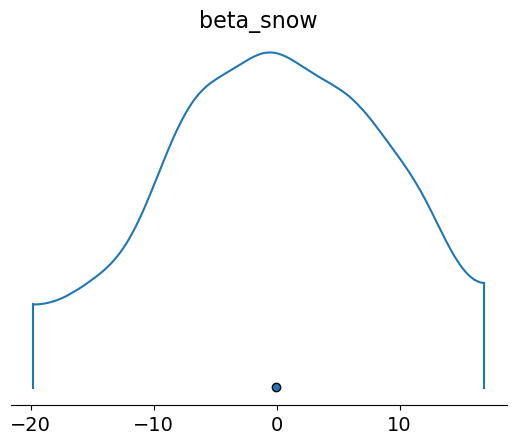

In [109]:
plot_all_prior_coefficients(model_uninformed_prior)

In [110]:
prior_summary = summarize_all_prior_coefficients(model_uninformed_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,8.09,6.01,0.00,18.31,0.20,0.20,975.41,914.21,NaN
beta_snow,-0.01,9.82,-19.82,16.90,0.32,0.22,949.33,983.44,NaN
alpha,-15.07,8.48,-29.21,0.29,0.28,0.18,923.07,943.76,NaN


In [111]:
summary = summarize_all_posterior_coefficients(model_uninformed_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.32,1.03,0.22,2.38,0.04,0.17,2089.36,981.51,1.0
alpha,-11.82,2.91,-17.13,-6.52,0.06,0.09,2685.18,2269.46,1.0
sigma,2.57,1.84,1.12,4.61,0.07,0.23,1652.12,1001.83,1.0


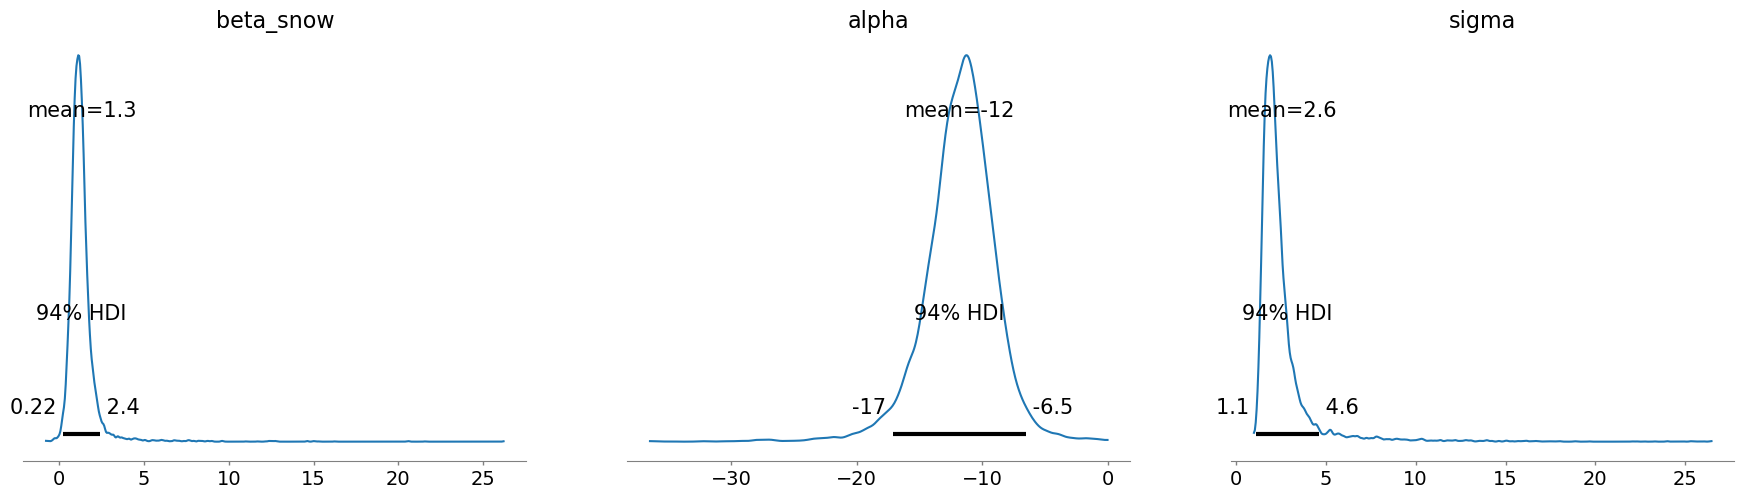

In [112]:
plot_all_posterior_coefficients(model_uninformed_idata)

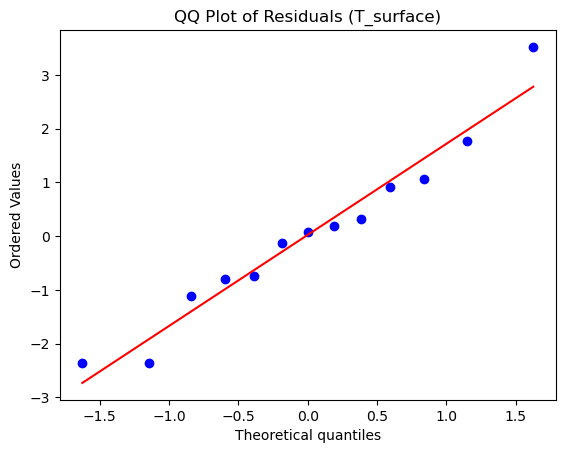

In [113]:
residuals = plot_residual_qq(
    model_uninformed_idata,
    T_surface,
    var_name="T_surface"
)

In [114]:
r2_table = compute_bayesian_r2(
    model_uninformed_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.488056,0.160937


In [115]:
loo_uninformed = compute_loo(model_uninformed_idata)
print(loo_uninformed)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -29.07     2.16
p_loo        3.09        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       12   92.3%
   (0.70, 1]   (bad)         1    7.7%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

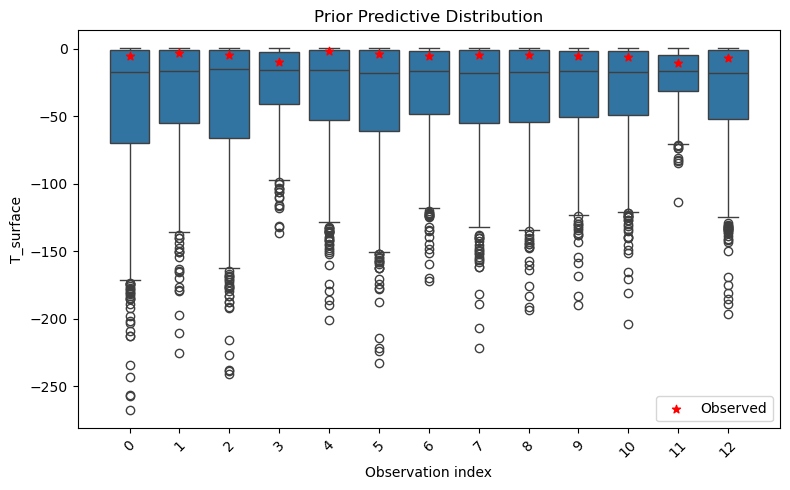

In [116]:
plot_prior_predictions(model_uninformed_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

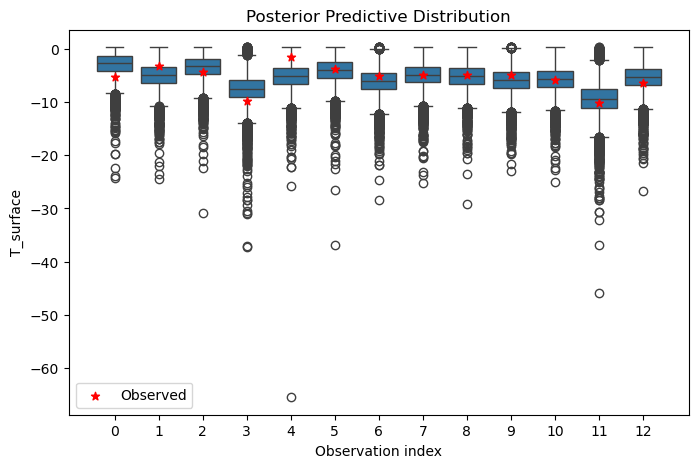

In [117]:
plot_predictions(model_uninformed_idata)

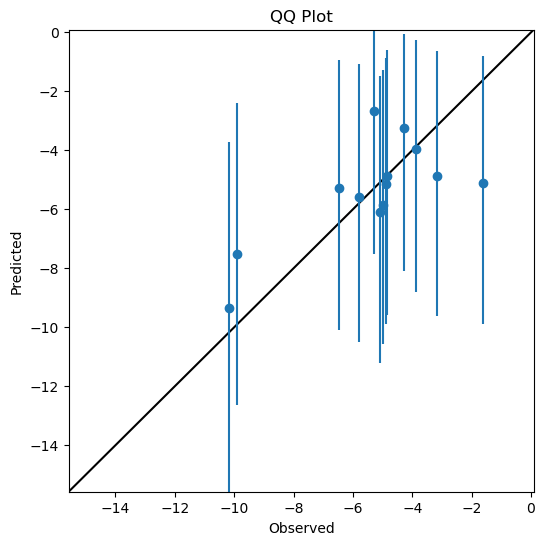

In [118]:
qqplot(model_uninformed_idata)

## Analytical Model

As a sensitivity analysis, we fitted an analytical Bayesian linear regression with conjugate priors to examine the relationship between snow depth and surface temperature. In this formulation, surface temperature was modeled as a linear function of snow depth under the assumption of Gaussian residual errors. 

The reduced predictive skill of the analytical approach likely reflects its stronger structural assumptions and limited flexibility compared to the numerically sampled MCMC framework. These results support the use of the MCMC-based models (above) as the primary analytical approach in this study.

In [119]:
y = df["T_surface"].values  # target variable
X = df[["snow_10cm"]].values  # predictor
n = len(y)

X = np.column_stack([np.ones(n), X])

# Priors: beta ~ N(mu_prior, sigma_prior^2)
mu_prior = np.array([-13.2, 0])   
sigma_prior = np.array([2.0, 2.0])
Lambda_prior = np.diag(1 / sigma_prior**2)  


In [120]:
sigma = 2.0
sigma2 = sigma**2

In [121]:
# Posterior covariance
Sigma_post = np.linalg.inv((X.T @ X) / sigma2 + Lambda_prior)

# Posterior mean
mu_post = Sigma_post @ ((X.T @ y) / sigma2 + Lambda_prior @ mu_prior)

print("Posterior mean:", mu_post)
print("Posterior covariance matrix:\n", Sigma_post)

Posterior mean: [-12.19842812   1.21950698]
Posterior covariance matrix:
 [[ 2.07806805 -0.35095039]
 [-0.35095039  0.06871756]]


In [122]:
samples = np.random.multivariate_normal(mu_post, Sigma_post, size=1000)

In [123]:
# --- Analytical posterior predictive R² ---

# Sample beta from analytical posterior
n_draws = 1000
beta_samples = np.random.multivariate_normal(mu_post, Sigma_post, size=n_draws)

# Compute R² for each draw
r2_analytical = np.zeros(n_draws)
y_true = y  # observed T_surface
y_mean = np.mean(y_true)

for i in range(n_draws):
    y_pred = X @ beta_samples[i]  # predicted T_surface for this beta sample
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - y_mean)**2)
    r2_analytical[i] = 1 - ss_res / ss_tot

# Summarize
r2_analytical_mean = np.mean(r2_analytical)
r2_analytical_sd = np.std(r2_analytical)
r2_analytical_ci = np.percentile(r2_analytical, [2.5, 97.5])

print("Analytical posterior predictive R²:")
print(f"Mean: {r2_analytical_mean:.3f}, SD: {r2_analytical_sd:.3f}, 95% CI: [{r2_analytical_ci[0]:.3f}, {r2_analytical_ci[1]:.3f}]")


Analytical posterior predictive R²:
Mean: 0.400, SD: 0.096, 95% CI: [0.121, 0.490]


## Vegetation influence 
model_depth grouped by vegetation 

To evaluate whether vegetation type influenced ground surface temperatures, we tested a hierarchical Bayesian model including varying intercepts for vegetation class. The model structure remained identical to the primary \textit{depth} model. 
Posterior estimates showed substantial overlap among vegetation group intercepts. Mean intercept estimates ranged from -12.8°C for dry tundra to -12.0°C for moist shrub, with overlapping highest density intervals across all groups. The estimated group-level standard deviation was relatively small 0.8°C, SD: 0.5°C, indicating limited between-group variability.
These results confirm that, within the limited environmental variability captured by the sensor network, vegetation does not emerge as a statistically identifiable control on ground surface temperature.

In [124]:
veg_codes, veg_idx = np.unique(df["vegetation"], return_inverse=True)
n_veg = len(veg_codes)

In [125]:
veg_codes

array(['dry shrub', 'dry tundra', 'moist shrub', 'moist tundra'],
      dtype=object)

0 = dry shrub
1 = dry tundra
2 = moist shrub
3 = moist tundra

In [126]:
T_surface = df["T_surface"].values

with pm.Model() as model_veg:
    
    # Constants
    T_max = 0.3 # theoretical maximum temperature measurement

    # Data
    snow = pm.Data("snow", df["snow_10cm"].values)
    veg = pm.Data("veg", veg_idx)

    # Global intercept
    alpha_mu = pm.Normal("alpha_mu", mu=-13.2, sigma=1.5)

    # Between-vegetation variability
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=1)

    # Vegetation-specific intercepts
    # We use a non-centered reparameterization here to improve sampling
    alpha = pm.Normal("alpha", mu=0, sigma=1, shape=n_veg)
    alpha_transformed = pt.minimum(alpha_mu + sigma_alpha * alpha, T_max)

    # Snow slope (pooled)
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,        
        sigma=1
    )

    # Linear predictor
    mu = alpha_transformed[veg] + beta_snow * snow

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # Residual
    sigma = pm.HalfNormal("sigma", sigma=4)

    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=T_max,
        observed=T_surface
    )

In [127]:
model_veg_prior,model_veg_idata = run_model(model_veg)

Sampling: [T_surface, alpha, alpha_mu, beta_snow, sigma, sigma_alpha]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha_mu, sigma_alpha, alpha, beta_snow, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 7 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Sampling: [T_surface]


Output()

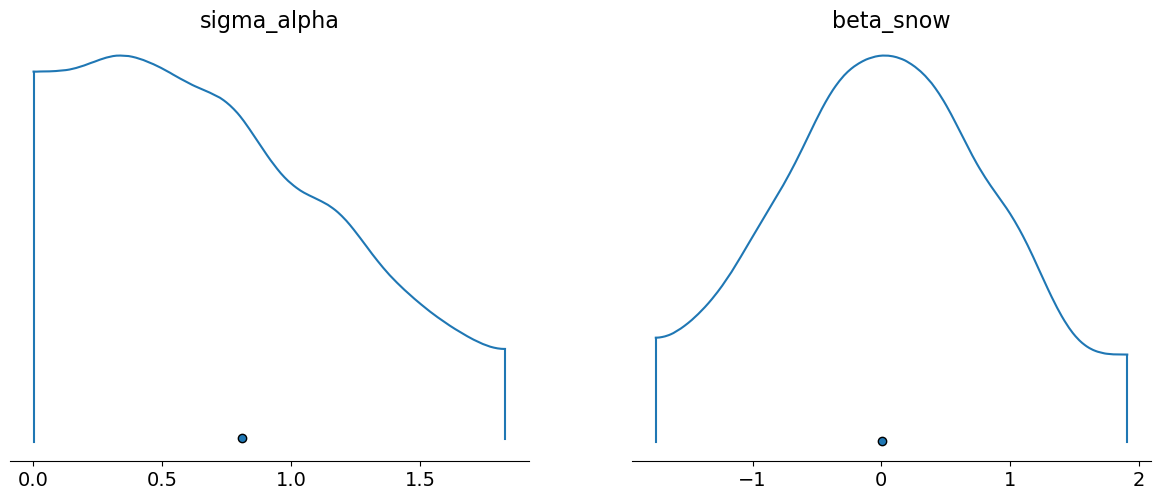

In [128]:
plot_all_prior_coefficients(model_veg_prior)

In [129]:
prior_summary = summarize_all_prior_coefficients(model_veg_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,3.15,2.35,0.00,7.49,0.07,0.06,952.97,980.87,NaN
sigma_alpha,0.81,0.60,0.00,1.83,0.02,0.02,975.41,914.21,NaN
beta_snow,0.00,0.97,-1.75,1.91,0.03,0.02,930.37,930.87,NaN
alpha[0],-0.01,0.99,-1.93,1.67,0.03,0.02,984.53,746.95,NaN
alpha[1],0.04,1.02,-1.74,1.92,0.03,0.02,1013.46,873.93,NaN
alpha[2],-0.04,0.98,-1.81,1.72,0.03,0.02,900.67,935.83,NaN
alpha[3],0.03,1.00,-1.71,1.94,0.03,0.03,904.01,752.12,NaN


In [130]:
summary = summarize_all_posterior_coefficients(model_veg_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[0],0.28,0.92,-1.46,1.99,0.01,0.01,12769.14,9226.27,1.0
alpha[1],-0.56,0.91,-2.23,1.20,0.01,0.01,8658.86,8279.32,1.0
alpha[2],0.33,0.90,-1.37,2.04,0.01,0.01,12023.59,8482.13,1.0
alpha[3],0.25,0.86,-1.36,1.88,0.01,0.01,13077.16,8597.29,1.0
beta_snow,1.26,0.24,0.81,1.71,0.00,0.00,6511.42,6102.62,1.0
sigma_alpha,0.73,0.51,0.00,1.63,0.01,0.00,5196.19,4312.69,1.0
sigma,1.95,0.59,1.04,2.98,0.01,0.01,6642.17,6675.56,1.0


0 = dry shrub
1 = dry tundra
2 = moist shrub
3 = moist tundra

In [131]:
alpha_within_rope = ((model_veg_idata.posterior["alpha"] <= 0.1) * (model_veg_idata.posterior["alpha"] >= -0.1)).mean(dim=["chain", "draw"])
alpha_above_rope = (model_veg_idata.posterior["alpha"] >= 0.1).mean(dim=["chain", "draw"])
alpha_below_rope = (model_veg_idata.posterior["alpha"] <= 0.1).mean(dim=["chain", "draw"])
print(alpha_within_rope.values)
print(alpha_above_rope.values)
print(alpha_below_rope.values)

[0.08383333 0.07141667 0.08616667 0.08533333]
[0.58433333 0.22525    0.607      0.57916667]
[0.41566667 0.77475    0.393      0.42083333]


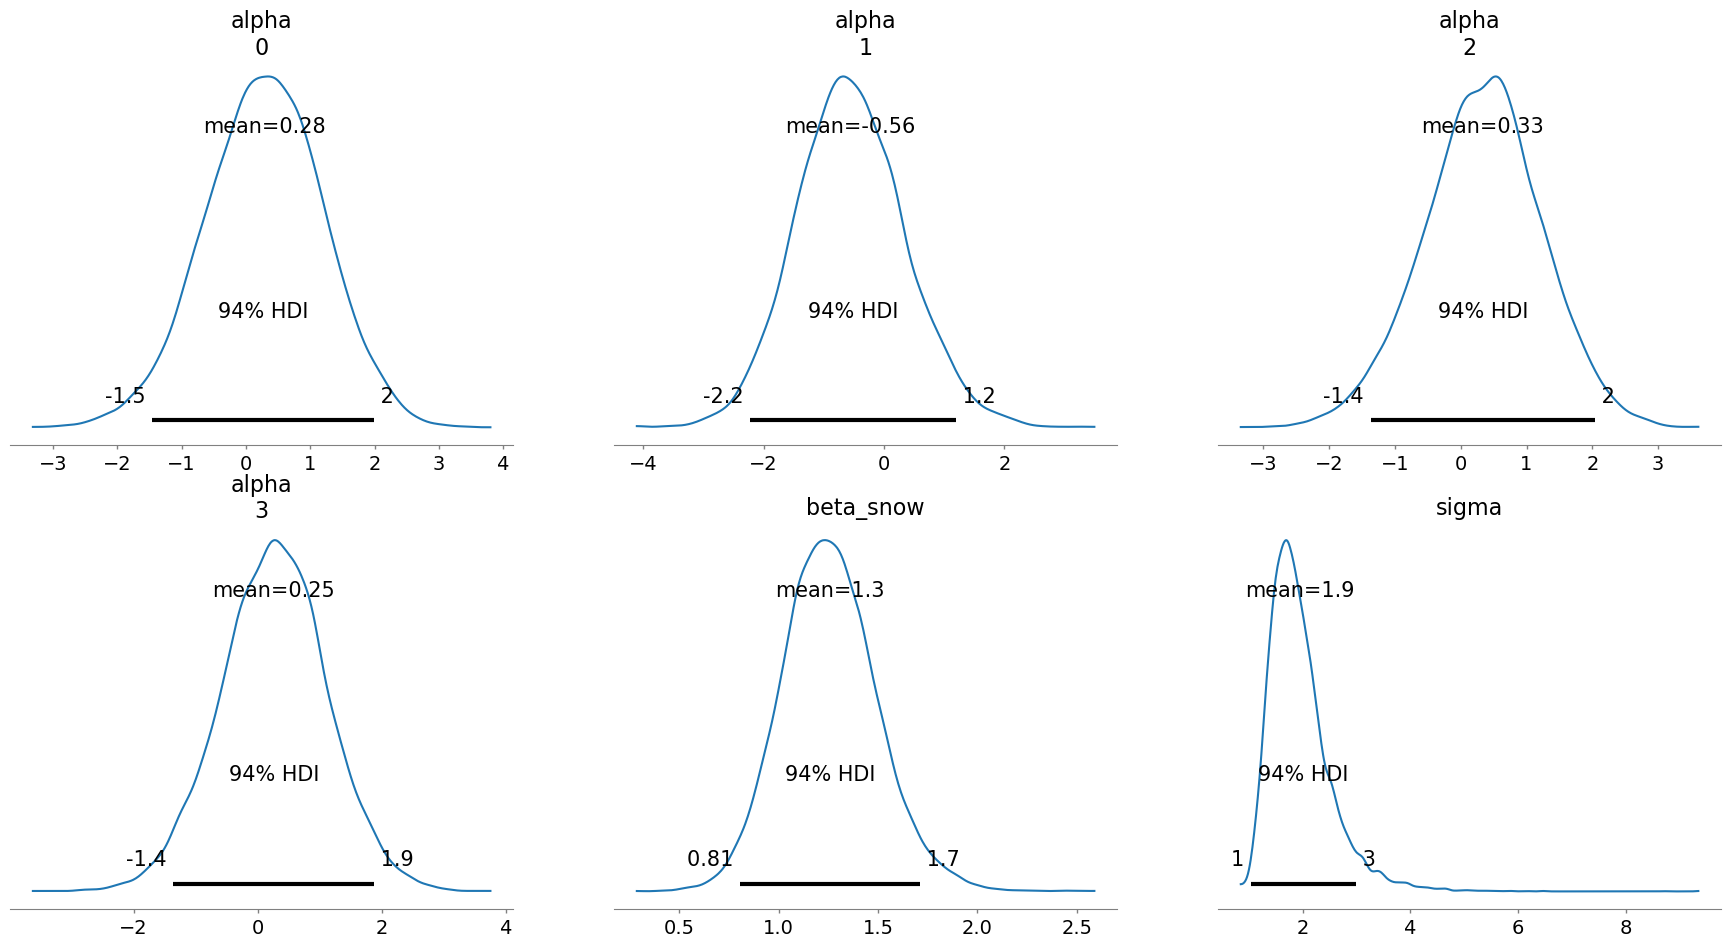

In [132]:
plot_all_posterior_coefficients(model_veg_idata)

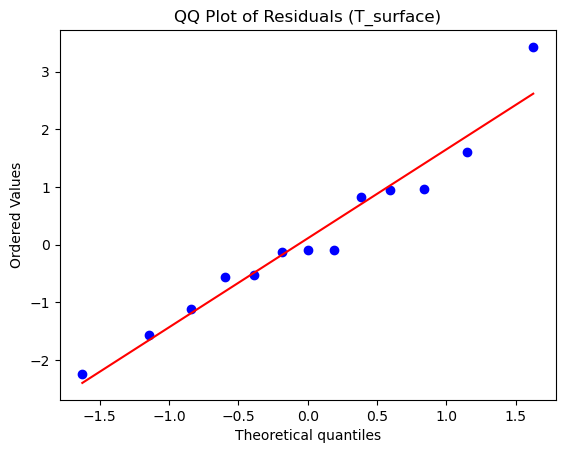

In [133]:
residuals = plot_residual_qq(
    model_veg_idata,
    T_surface,
    var_name="T_surface"
)

In [134]:
r2_table = compute_bayesian_r2(
    model_veg_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.590384,0.089543


In [135]:
loo_veg = compute_loo(model_veg_idata)
print(loo_veg)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -27.71     2.66
p_loo        3.32        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       11   84.6%
   (0.70, 1]   (bad)         2   15.4%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

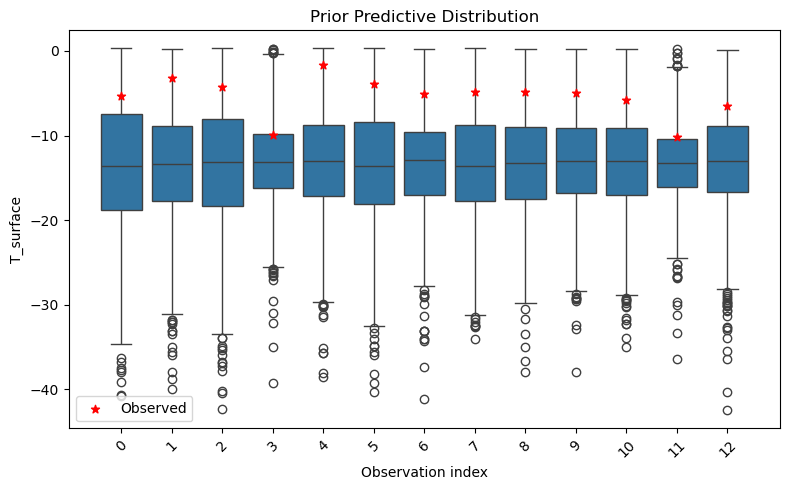

In [136]:
plot_prior_predictions(model_veg_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

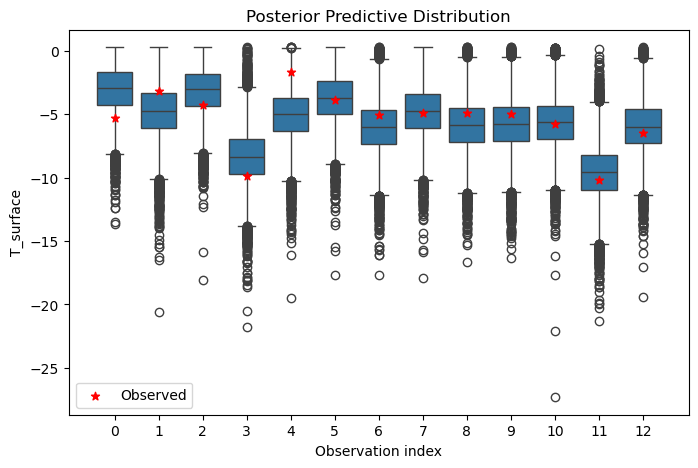

In [137]:
plot_predictions(model_veg_idata)

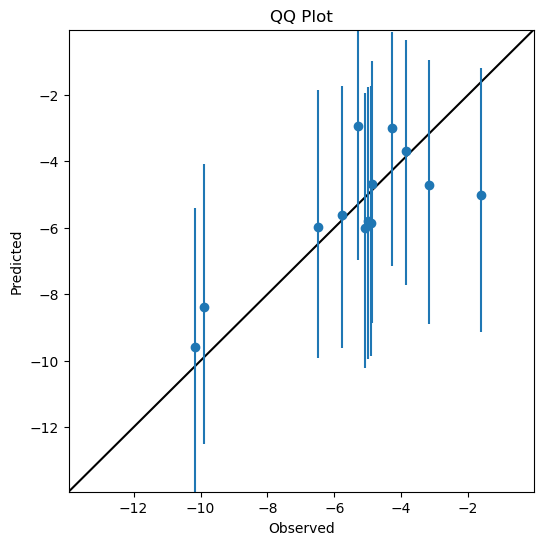

In [138]:
qqplot(model_veg_idata)

In [139]:
comparison_results = []

for name, idata in models.items():
    
    # R²
    r2 = compute_bayesian_r2(idata, T_surface)
    r2_mean = float(r2["R2_mean"].values[0])
    r2_sd   = float(r2["R2_sd"].values[0])
    
    # LOO
    loo = compute_loo(idata)
    
    comparison_results.append({
        "Model": name,
        "R2_mean": r2_mean,
        "R2_sd": r2_sd,
        "elpd_loo": loo.elpd_loo,
        "p_loo": loo.p_loo,
        "loo_se": loo.se
    })

comparison_table = pd.DataFrame(comparison_results)


/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/py

In [140]:
comparison_table = comparison_table.sort_values(
    by="elpd_loo",
    ascending=False
)

comparison_table

,Model,R2_mean,R2_sd,elpd_loo,p_loo,loo_se
0,depth,0.542714,0.082721,-27.790881,2.415125,2.560624
2,depth_density,0.544785,0.080513,-27.832880,2.418249,2.523703
5,depth_density_topography,0.575053,0.076923,-28.955392,3.304491,2.255143
3,depth_topography,0.575135,0.077101,-28.980673,3.332868,2.252894
1,density,0.003502,0.004887,-31.604638,2.082991,2.624427
6,topography,0.144291,0.099045,-32.496783,2.756102,2.513810
4,density_topography,0.147249,0.100627,-32.544438,2.824636,2.499448


In [141]:
for name, idata in models.items():
    loo = az.loo(idata)
    k_vals = loo.pareto_k.values
    
    print(f"\nModel: {name}")
    print("Max k:", np.max(k_vals))
    print("k > 0.7:", np.sum(k_vals > 0.7))
    print("k > 1.0:", np.sum(k_vals > 1.0))



Model: depth
Max k: 0.666295117591656
k > 0.7: 0
k > 1.0: 0

Model: density
Max k: 0.6169087136057606
k > 0.7: 0
k > 1.0: 0

Model: depth_density
Max k: 0.7463256333108823
k > 0.7: 1
k > 1.0: 0

Model: depth_topography
Max k: 0.874593340468712
k > 0.7: 2
k > 1.0: 0

Model: density_topography
Max k: 0.7296146661830253
k > 0.7: 3
k > 1.0: 0

Model: depth_density_topography
Max k: 0.7837033540396798
k > 0.7: 2
k > 1.0: 0

Model: topography
Max k: 0.9180002262802831
k > 0.7: 1
k > 1.0: 0


/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/py

In [142]:
models = {
    "Depth": model_depth_idata,
    "Depth+Density": model_depth_density_idata,
    "Depth+Topo": model_depth_topography_idata,
    "Depth+Density+Topo": model_depth_density_topography_idata,
    "Density": model_density_idata,
}

predictor_labels = {
    "beta_snow": "Snow depth",
    "beta_density": "Bulk density",
    "beta_slope": "Slope",
    "beta_sin": "Aspect sin",
    "beta_cos": "Aspect cos",
    "beta_elev": "Elevation"
}


In [143]:
rows = []

for model_name, idata in models.items():
    
    summary = az.summary(idata, hdi_prob=0.95)
    
    for param in summary.index:
        
        if param.startswith("beta_"):
            
            rows.append({
                "Model": model_name,
                "Predictor": predictor_labels.get(param, param),
                "Mean": summary.loc[param, "mean"],
                "Lower": summary.loc[param, "hdi_2.5%"],
                "Upper": summary.loc[param, "hdi_97.5%"]
            })

coef_df = pd.DataFrame(rows)



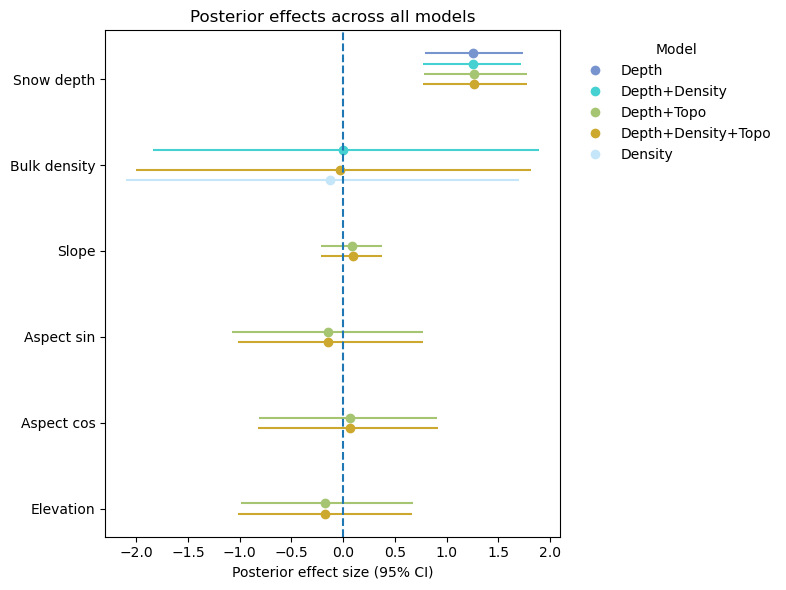

In [144]:
plt.figure(figsize=(8,6))

predictors = list(predictor_labels.values())
y_base = np.arange(len(predictors))

offset = 0.12

models_list = list(models.keys())

colors = {
    "Depth": "#7794cf",
    "Depth+Density": "#45d1d1",
    "Depth+Topo": "#a6c573",
    "Depth+Density+Topo": "#CDA82F",
    "Density": "#c5e6f8",
}

for j, predictor in enumerate(predictors):
    
    y_center = y_base[j]
    
    for i, model_name in enumerate(models_list):
        
        subset = coef_df[
            (coef_df["Model"] == model_name) &
            (coef_df["Predictor"] == predictor)
        ]
        
        if len(subset) == 0:
            continue  
        
        y_pos = y_center + (i - len(models_list)/2) * offset
        
        plt.hlines(
            y=y_pos,
            xmin=subset["Lower"].values[0],
            xmax=subset["Upper"].values[0],
            color=colors[model_name]
        )
        
        plt.plot(
            subset["Mean"].values[0],
            y_pos,
            "o",
            color=colors[model_name]
        )

plt.axvline(0, linestyle="--")
plt.yticks(y_base, predictors)
plt.gca().invert_yaxis()

plt.xlabel("Posterior effect size (95% CI)")
plt.title("Posterior effects across all models")

from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=colors[model], markersize=8,
           label=model)
    for model in models_list
]

plt.legend(
    handles=legend_elements,
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    title="Model")

plt.tight_layout()
plt.show()

Posterior mean effects and 94% highest density intervals (HDI) for all candidate
Bayesian models. Dots represent posterior means and horizontal bars indicate 94% HDIs. The col-
ors represent the different models and also illustrate which predictors were included in which model.
Positive coefficients indicate an increase in the response variable (ground surface temperature) with
increasing predictor values (i.e., a warming effect), whereas negative coefficients indicate a cooling
effect. Increased snow depth has a warming effect in all four models, with consistent posterior means of
1.25 to 1.27 °C per 10 cm. Snow density effects are centered on zero, with wide intervals, in all models, including the model with density as the only predictor. Slope, aspect and elevation effects span across positive and negative values.

# Review

## Inclusion of soil moisture as a predictor

Upon a reviewers suggestion we added soil moisture to our models as soil liquid water content prior to soil freezing may influence the duration of the zero-curtain period and the timing of soil cooling. We included soil moisture as an additional predictor in our depth+density+topo model, using the last available soil moisture measurement at each sensor before the soil froze. However, including soil moisture did not improve model performance or predictive skill. The estimated effect of soil moisture is 0.3°C (94% HDI: -0.4 to 1.0).

In [145]:
df["soil_moist"] = df["soil_moisture"] / 0.1
df["soil_moist_c"] = df["soil_moist"] - df["soil_moist"].mean()

In [146]:
T_surface = df["T_surface"].values

with pm.Model() as model_depth_density_topography_moisture:

    # -------------------------
    # Data
    # -------------------------
    snow = pm.Data("snow", df["snow_10cm"].values)      
    density = pm.Data("density", df["density_01_c"].values) 
    slope = pm.Data("slope", df["slope_c"].values)
    elev = pm.Data("elev", df["elev_10m_c"].values)
    asp_sin = pm.Data("asp_sin", df["aspect_sin_c"].values)
    asp_cos = pm.Data("asp_cos", df["aspect_cos_c"].values)
    soil_moist = pm.Data("soil_moist", df["soil_moist_c"].values)

    # -------------------------
    # Intercept
    # -------------------------
    alpha = pm.TruncatedNormal(
        "alpha",
        mu=-13.2,        
        sigma=1.5,      
        upper=0.3       
    )

    # -------------------------
    # Slopes
    # -------------------------
    beta_snow = pm.Normal(
        "beta_snow", 
        mu=0,        
        sigma=1
    )

    beta_density = pm.Normal(
        "beta_density",
        mu=0,         
        sigma=1
    )

    beta_slope = pm.Normal(
        "beta_slope",
        mu=0.0,         
        sigma=0.5       
    )

    beta_elev = pm.Normal(
        "beta_elev",
        mu=0.0,
        sigma=0.5
    )

    beta_sin = pm.Normal(
        "beta_sin",
        mu=0.0,
        sigma=0.5
    )

    beta_cos = pm.Normal(
        "beta_cos",
        mu=0.0,
        sigma=0.5
    )
    
    beta_soil_moist = pm.Normal(
        "beta_soil_moist",
        mu=0.0, 
        sigma=0.5
    )

    # -------------------------
    # Residual standard deviation
    # -------------------------
    sigma = pm.HalfNormal(
        "sigma",
        sigma=4   
    )

    # -------------------------
    # Linear predictor
    # -------------------------
    mu = (
        alpha
        + beta_snow * snow
        + beta_density * density
        + beta_slope * slope
        + beta_elev * elev
        + beta_sin * asp_sin
        + beta_cos * asp_cos
        + beta_soil_moist * soil_moist
    )

    # Store the expected value so that Bayesian R² can be computed from it
    # (see compute_bayesian_r2)
    mu = pm.Deterministic("mu", mu)

    # -------------------------
    # Likelihood (truncated at upper bound 0.3°C)
    # -------------------------
    T_obs = pm.TruncatedNormal(
        "T_surface",
        mu=mu,
        sigma=sigma,
        upper=0.3,
        observed=T_surface
    )


In [147]:
model_depth_density_topography_moisture_prior, model_depth_density_topography_moisture_idata = run_model(model_depth_density_topography_moisture)

Sampling: [T_surface, alpha, beta_cos, beta_density, beta_elev, beta_sin, beta_slope, beta_snow, beta_soil_moist, sigma]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta_snow, beta_density, beta_slope, beta_elev, beta_sin, beta_cos, beta_soil_moist, sigma]


Output()

Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 7 seconds.


Sampling: [T_surface]


Output()

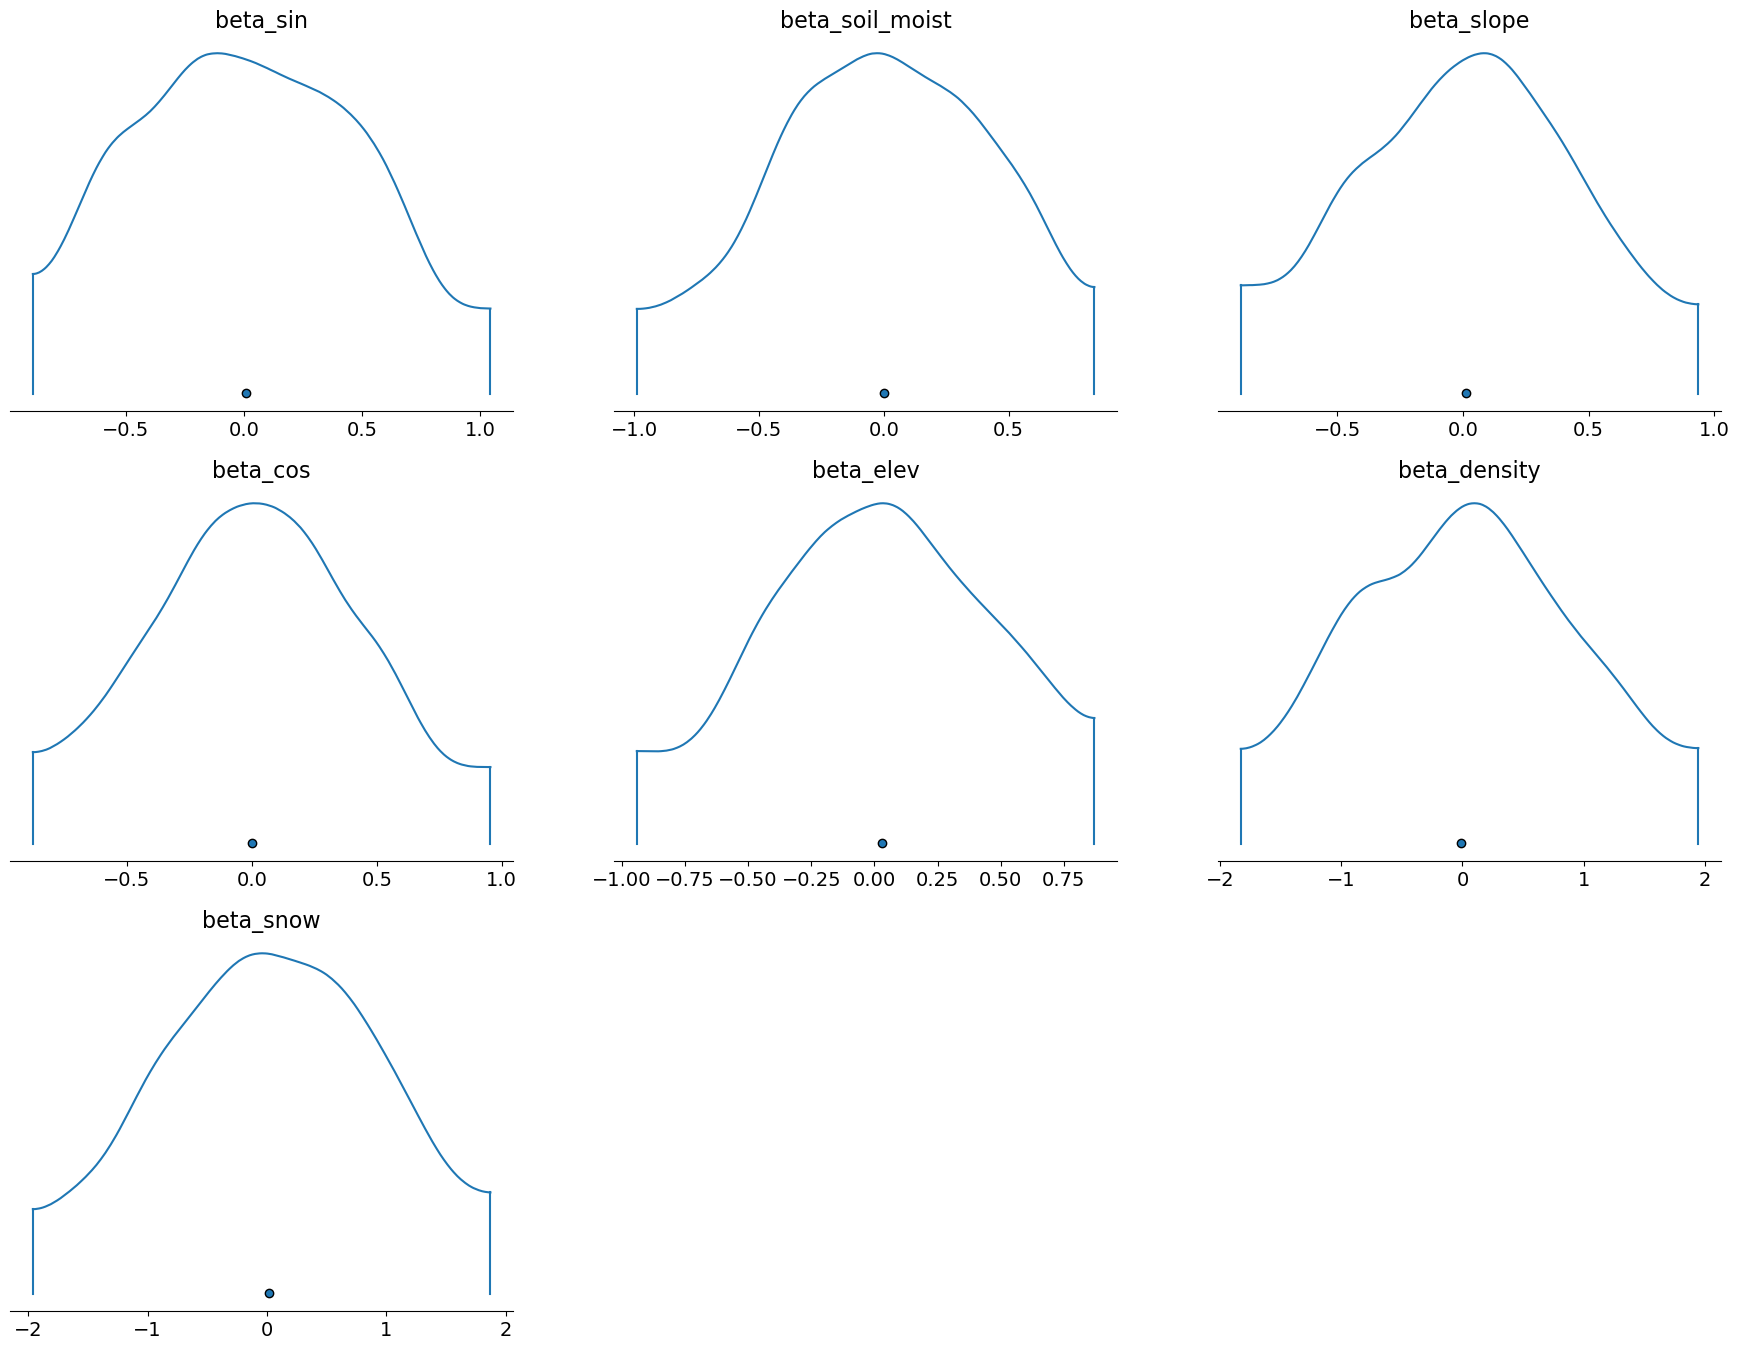

In [148]:
plot_all_prior_coefficients(model_depth_density_topography_moisture_prior)

In [149]:
prior_summary = summarize_all_prior_coefficients(model_depth_density_topography_moisture_prior)
prior_summary

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_sin,0.01,0.53,-0.90,1.05,0.02,0.01,1020.11,778.10,NaN
beta_soil_moist,-0.00,0.49,-0.99,0.85,0.02,0.01,949.33,983.44,NaN
beta_slope,0.01,0.49,-0.88,0.94,0.02,0.01,872.25,914.55,NaN
beta_cos,0.00,0.49,-0.88,0.96,0.02,0.01,930.37,930.87,NaN
beta_elev,0.03,0.50,-0.94,0.87,0.02,0.01,1008.75,982.80,NaN
beta_density,-0.01,1.02,-1.83,1.95,0.04,0.02,825.98,880.24,NaN
sigma,3.24,2.41,0.00,7.32,0.08,0.08,975.41,914.21,NaN
beta_snow,0.01,1.02,-1.96,1.88,0.03,0.02,984.18,983.28,NaN
alpha,-13.20,1.48,-15.92,-10.34,0.04,0.03,1080.77,903.10,NaN


In [150]:
summary = summarize_all_posterior_coefficients(model_depth_density_topography_moisture_idata)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,1.27,0.26,0.80,1.74,0.00,0.00,7985.98,6834.60,1.0
beta_density,-0.07,0.97,-1.85,1.83,0.01,0.01,15056.95,8737.94,1.0
beta_slope,0.08,0.15,-0.19,0.36,0.00,0.00,12247.71,7908.74,1.0
beta_elev,-0.11,0.43,-0.91,0.69,0.00,0.00,13882.45,9523.06,1.0
beta_sin,-0.14,0.46,-1.01,0.73,0.00,0.00,14218.14,8184.20,1.0
beta_cos,0.03,0.44,-0.76,0.90,0.00,0.00,17060.46,8258.39,1.0
beta_soil_moist,0.30,0.36,-0.39,0.96,0.00,0.00,15106.59,8150.30,1.0
alpha,-12.32,1.23,-14.71,-10.09,0.01,0.01,9697.26,8397.57,1.0
sigma,2.16,0.72,1.14,3.47,0.01,0.01,6396.81,7018.81,1.0


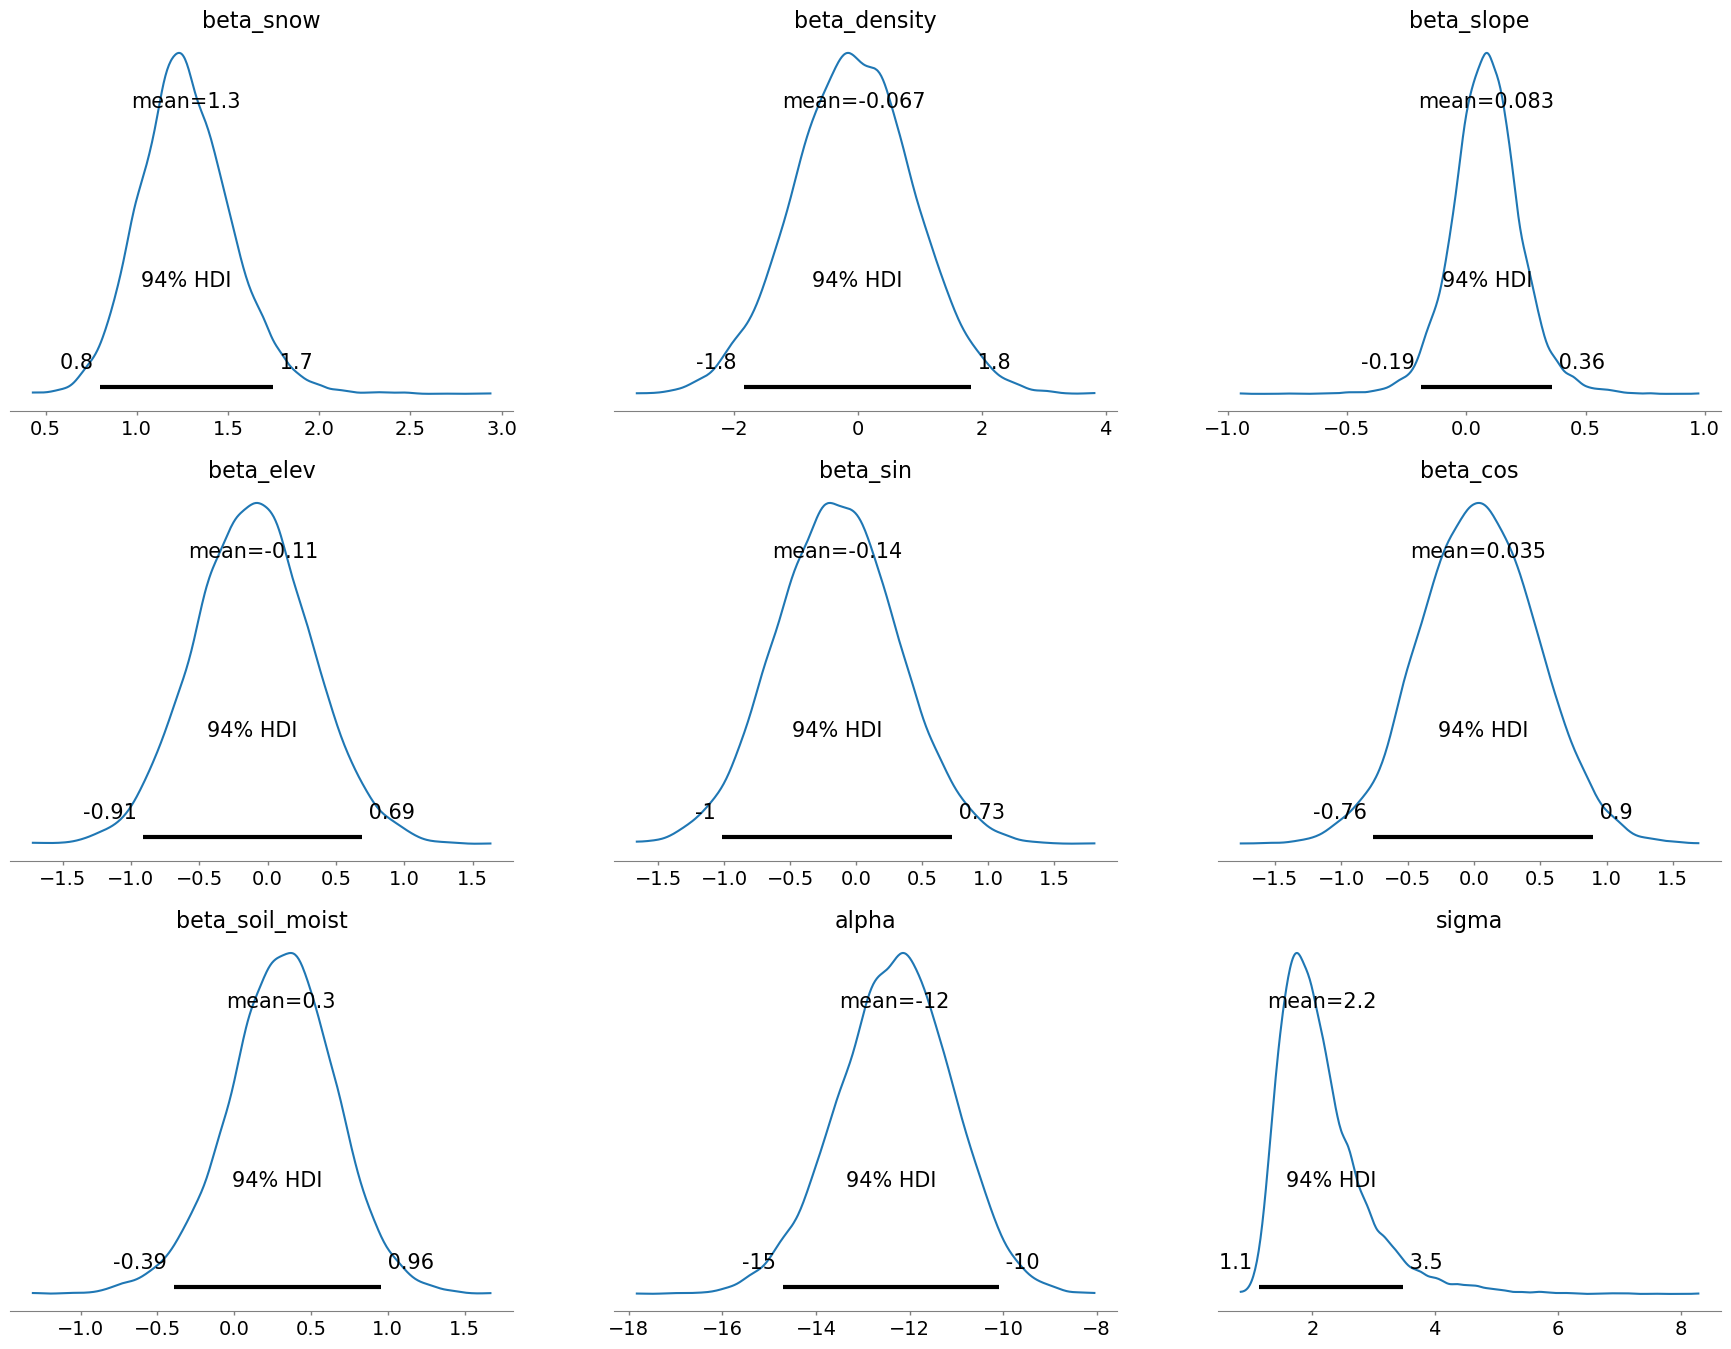

In [151]:
plot_all_posterior_coefficients(model_depth_density_topography_moisture_idata)

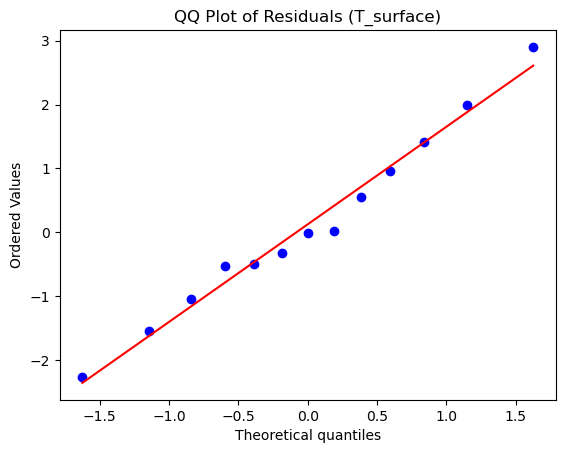

In [152]:
residuals = plot_residual_qq(
    model_depth_density_topography_moisture_idata,
    T_surface,
    var_name="T_surface"
)

In [153]:
r2_table = compute_bayesian_r2(
    model_depth_density_topography_moisture_idata,
    T_surface
)
r2_table


,R2_mean,R2_sd
0,0.605312,0.077094


In [154]:
loo_depth_density_topography_moisture = compute_loo(model_depth_density_topography_moisture_idata)
print(loo_depth_density_topography_moisture)

Computed from 12000 posterior samples and 13 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -28.81     1.76
p_loo        3.65        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       11   84.6%
   (0.70, 1]   (bad)         2   15.4%
   (1, Inf)   (very bad)    0    0.0%



/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Prior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

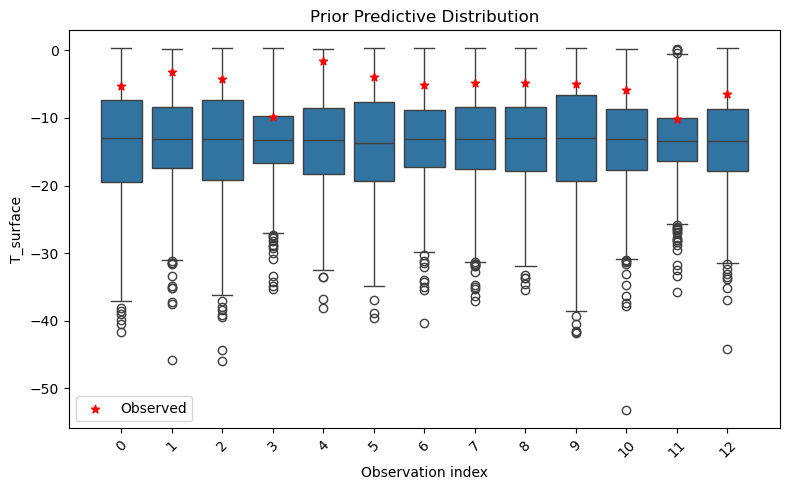

In [155]:
plot_prior_predictions(model_depth_density_topography_moisture_prior, var="T_surface")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Posterior Predictive Distribution'}, xlabel='Observation index', ylabel='T_surface'>)

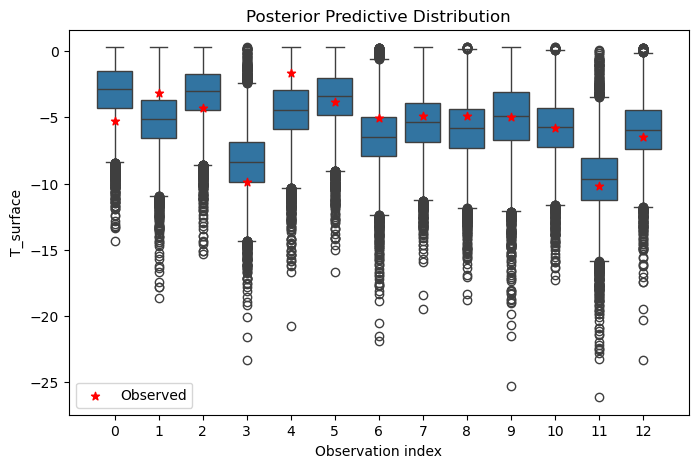

In [156]:
plot_predictions(model_depth_density_topography_moisture_idata)

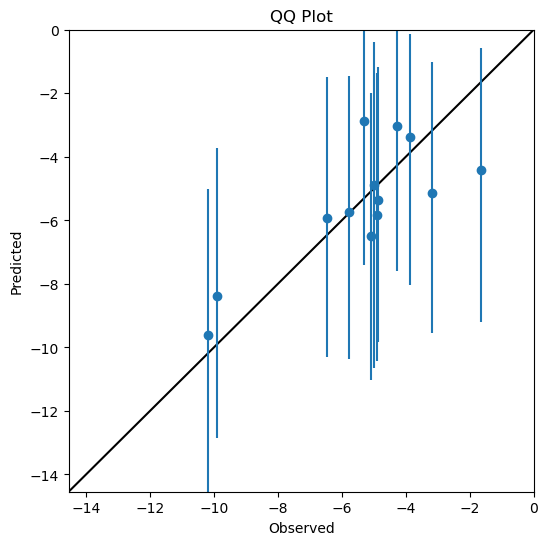

In [157]:
qqplot(model_depth_density_topography_moisture_idata)

In [158]:
models = {
    "depth": model_depth_idata,
    "density": model_density_idata,
    "depth_density": model_depth_density_idata,
    "depth_topography": model_depth_topography_idata,
    "density_topography": model_density_topography_idata,
    "depth_density_topography": model_depth_density_topography_idata,
    "topography": model_topography_idata,
    "depth_density_topography_moisture":model_depth_density_topography_moisture_idata 
}



In [159]:
comparison_results = []

for name, idata in models.items():
    
    # R²
    r2 = compute_bayesian_r2(idata, T_surface)
    r2_mean = float(r2["R2_mean"].values[0])
    r2_sd   = float(r2["R2_sd"].values[0])
    
    # LOO
    loo = compute_loo(idata)
    
    comparison_results.append({
        "Model": name,
        "R2_mean": r2_mean,
        "R2_sd": r2_sd,
        "elpd_loo": loo.elpd_loo,
        "p_loo": loo.p_loo,
        "loo_se": loo.se
    })

comparison_table = pd.DataFrame(comparison_results)


/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/py

/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


## Investigating the relationhip between snow depth and density

Here we investigate the correlation between snow depth and density in the dataset. We can see from a simple scatter plot that the two variables are not colinear.

<Axes: xlabel='bulk_density', ylabel='snow_depth'>

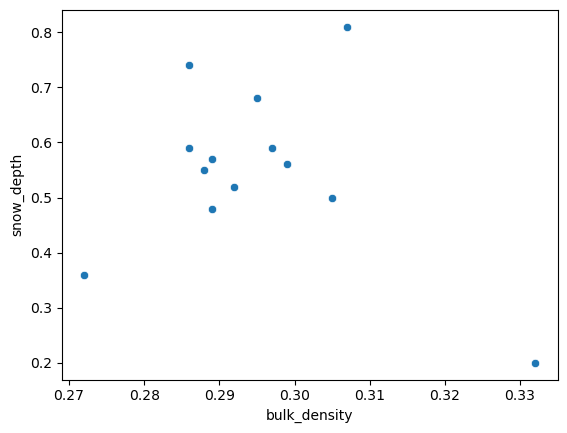

In [160]:
sns.scatterplot(df, x="bulk_density", y="snow_depth")

Using all of the TOMST sensors, we get a negative correlation between snow depth and density. However, this is affected by the presence of a possible outlier (TOMST 115x).

In [161]:
df[["bulk_density", "snow_depth"]].corr(method="pearson")

,bulk_density,snow_depth
bulk_density,1.000000,-0.281327
snow_depth,-0.281327,1.000000


In [162]:
df[["bulk_density", "snow_depth"]].corr(method="kendall")

,bulk_density,snow_depth
bulk_density,1.000000,-0.039217
snow_depth,-0.039217,1.000000


Dropping this sensor, we get a stronger positive correlation of ~0.5. This apparent correlation is itself clearly the result of just two measurements at the extrema: TOMST 6 and TOMST 15. The majority of points in the central mass of the distribution do not show any obvious linear relationship.

<Axes: xlabel='bulk_density', ylabel='snow_depth'>

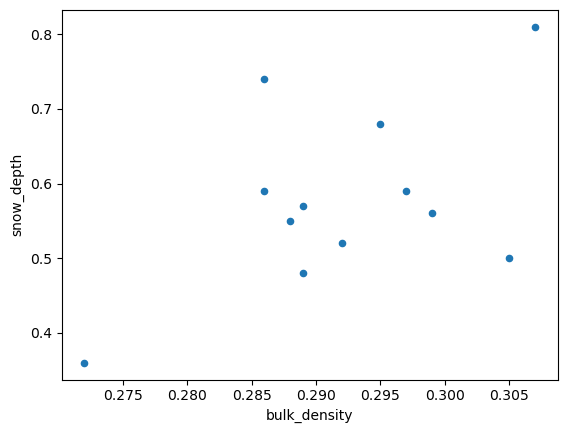

In [163]:
df.drop(11).plot.scatter(x="bulk_density", y="snow_depth")

In [164]:
df.drop(11)[["snow_depth", "bulk_density"]].corr()

,snow_depth,bulk_density
snow_depth,1.000000,0.516838
bulk_density,0.516838,1.000000


Dropping these points, we again get a negative correlation, demonstrating that snow depth and density do not have a trivial relationship in this dataset.

In [165]:
df.drop([0, 3, 11])[["snow_depth", "bulk_density"]].corr()

,snow_depth,bulk_density
snow_depth,1.000000,-0.308387
bulk_density,-0.308387,1.000000


### Posterior correlation between the depth and density coefficients

If the correlation between the predictors were what limits the density estimate, the joint posterior of `beta_snow` and `beta_density` would show strong dependence. We check this for the depth + density model.

Posterior correlation(beta_snow, beta_density) = 0.05


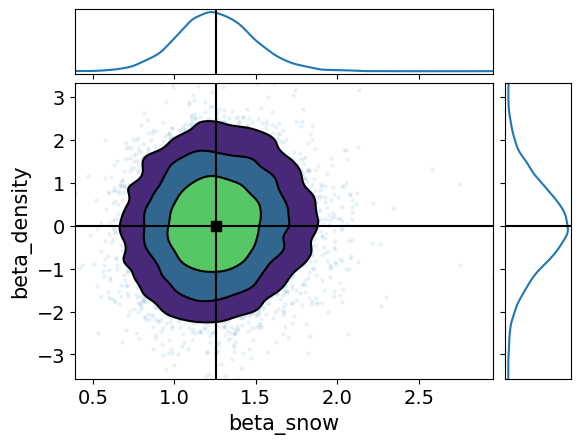

In [166]:
coef_names = ["beta_snow", "beta_density"]
post = model_depth_density_idata.posterior[coef_names].stack(sample=("chain", "draw"))
coef_corr = np.corrcoef(post["beta_snow"].values, post["beta_density"].values)[0, 1]
print(f"Posterior correlation(beta_snow, beta_density) = {coef_corr:.2f}")

az.plot_pair(
    model_depth_density_idata,
    var_names=coef_names,
    kind=["scatter", "kde"],
    marginals=True,
    point_estimate="mean",
    scatter_kwargs={"alpha": 0.1},
)
plt.show()

The posterior joint for `beta_snow` and `beta_density` shows essentially no correlation (r = 0.05), so the weak correlation between the predictors themselves does not measurably limit the coefficient estimates. With uncentered density (rev0), the same model showed a moderate negative posterior correlation (r = -0.65); as we show below, this came from the intercept prior and not from the correlation between the predictors.

#### Sensitivity to the intercept prior width

We refit `depth_density` with the same prior mean for `alpha` (-13.2) and a range of prior standard deviations, once with uncentered density as in rev0 and once with centered density as in the main models. If the coefficient correlation comes from the intercept prior and not from the predictors, it should shrink as the prior is widened in the uncentered version, and be absent at every prior width in the centered version. The main models use `alpha ~ N(-13.2, 1.5)`.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma, beta_snow, beta_density]


Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 5 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (34 outputs left out)

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, sigma, beta_snow, beta_density]


Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 6 seconds.


There were 10 divergences after tuning. Increase `target_accept` or reparameterize.


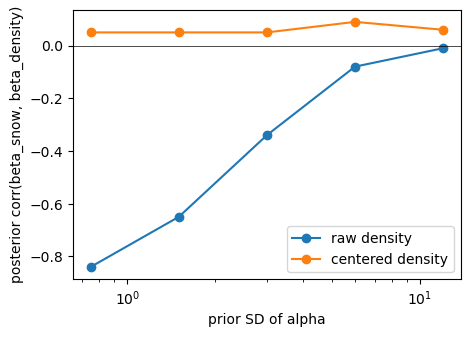

,density,alpha_prior_sd,"corr(beta_snow, beta_density)",beta_snow_mean,beta_snow_sd,beta_density_mean,beta_density_sd
0,raw,0.75,-0.84,1.13,0.31,0.51,0.58
1,raw,1.50,-0.65,1.12,0.31,0.45,0.63
2,raw,3.00,-0.34,1.08,0.33,0.33,0.76
3,raw,6.00,-0.08,1.03,0.36,0.13,0.89
4,raw,12.00,-0.01,0.99,0.38,0.02,0.94
5,centered,0.75,0.05,1.36,0.17,0.02,0.97
6,centered,1.50,0.05,1.26,0.24,0.02,0.96
7,centered,3.00,0.05,1.12,0.31,-0.02,0.96
8,centered,6.00,0.09,1.04,0.36,-0.04,0.97
9,centered,12.00,0.06,0.98,0.39,-0.05,0.96


In [167]:
alpha_sds = [0.75, 1.5, 3, 6, 12]
density_versions = {"raw": df["density_01"].values, "centered": df["density_01_c"].values}
rows = []
for density_name, density_values in density_versions.items():
    for alpha_sd in alpha_sds:
        with pm.Model():
            alpha = pm.TruncatedNormal("alpha", mu=-13.2, sigma=alpha_sd, upper=0.3)
            sigma = pm.HalfNormal("sigma", sigma=4)
            beta_snow = pm.Normal("beta_snow", mu=0, sigma=1)
            beta_density = pm.Normal("beta_density", mu=0, sigma=1)
            mu = alpha + beta_snow * df["snow_10cm"].values + beta_density * density_values
            pm.TruncatedNormal("T_surface", mu=mu, sigma=sigma, upper=0.3, observed=df["T_surface"].values)
            idata_sd = pm.sample(3000, tune=3000, target_accept=0.9, random_seed=20240409, progressbar=False)
        p = idata_sd.posterior
        b_s, b_d = p["beta_snow"].values.ravel(), p["beta_density"].values.ravel()
        rows.append({
            "density": density_name,
            "alpha_prior_sd": alpha_sd,
            "corr(beta_snow, beta_density)": np.corrcoef(b_s, b_d)[0, 1],
            "beta_snow_mean": b_s.mean(), "beta_snow_sd": b_s.std(),
            "beta_density_mean": b_d.mean(), "beta_density_sd": b_d.std(),
        })

alpha_sd_table = pd.DataFrame(rows).round(2)

fig, ax = plt.subplots(figsize=(5, 3.5))
for density_name, group in alpha_sd_table.groupby("density", sort=False):
    ax.semilogx(group["alpha_prior_sd"], group["corr(beta_snow, beta_density)"], "o-", label=f"{density_name} density")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("prior SD of alpha")
ax.set_ylabel("posterior corr(beta_snow, beta_density)")
ax.legend()
plt.show()
alpha_sd_table

With uncentered density, the correlation between the coefficients vanishes as the prior on `alpha` becomes less informative, and the density effect shrinks from 0.51 to 0.02. With uncentered density, the intercept is the temperature at zero density, so the prior on `alpha` effectively constrains a combination of the two slopes, which induced both the correlation and the apparent density effect in rev0. With centered density, the posterior correlation stays at 0.05 to 0.09 and the density effect stays centered on zero (-0.05 to 0.02, SD 0.96 to 0.97) at every prior width; the density posterior is essentially its prior, reflecting the narrow range of observed densities.

The snow depth effect does depend on the intercept prior in both versions: with centered density it decreases from 1.36 (SD 0.17) to 0.98 (SD 0.39) as the prior widens. This is expected, since snow depth remains uncentered so that `alpha` is the temperature without snow; the physically motivated prior on `alpha` therefore anchors the extrapolation of the depth trend to zero snow. The effect remains clearly positive at every prior width.

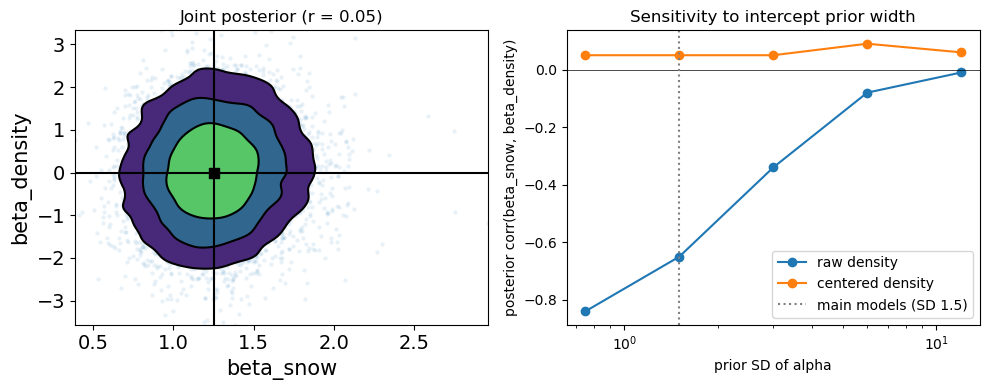

In [168]:
fig, (ax_joint, ax_sweep) = plt.subplots(1, 2, figsize=(10, 4))

# Left: joint posterior of the coefficients in the main (centered) depth + density model
az.plot_pair(
    model_depth_density_idata,
    var_names=["beta_snow", "beta_density"],
    kind=["scatter", "kde"],
    marginals=False,
    point_estimate="mean",
    scatter_kwargs={"alpha": 0.1},
    ax=ax_joint,
)
ax_joint.set_title(f"Joint posterior (r = {coef_corr:.2f})")

# Right: coefficient correlation versus intercept prior width
for density_name, group in alpha_sd_table.groupby("density", sort=False):
    ax_sweep.semilogx(group["alpha_prior_sd"], group["corr(beta_snow, beta_density)"], "o-", label=f"{density_name} density")
ax_sweep.axhline(0, color="k", lw=0.5)
ax_sweep.axvline(1.5, color="gray", ls=":", label="main models (SD 1.5)")
ax_sweep.set_xlabel("prior SD of alpha")
ax_sweep.set_ylabel("posterior corr(beta_snow, beta_density)")
ax_sweep.set_title("Sensitivity to intercept prior width")
ax_sweep.legend()

plt.tight_layout()
plt.show()

#### Fully centered parameterization (diagnostic only)

In the main models, snow depth remains uncentered so that `alpha` represents the surface temperature without snow and can be given the physically motivated prior. As a further check, we refit `depth_density` with snow depth also centered, and an intercept `alpha_c` that is the temperature at the mean predictor values. Here `alpha_c` gets a weak prior centered on the observed mean temperature, so this variant does not use the physically motivated `alpha` prior of the main models. It is not used for any reported result.

In [169]:
snow_c = df["snow_10cm"].values - df["snow_10cm"].mean()
density_c = df["density_01"].values - df["density_01"].mean()

with pm.Model() as model_depth_density_centered:
    alpha_c = pm.Normal("alpha_c", mu=df["T_surface"].mean(), sigma=5)
    sigma = pm.HalfNormal("sigma", sigma=4)
    beta_snow = pm.Normal("beta_snow", mu=0, sigma=1)
    beta_density = pm.Normal("beta_density", mu=0, sigma=1)
    mu = alpha_c + beta_snow * snow_c + beta_density * density_c
    pm.TruncatedNormal("T_surface", mu=mu, sigma=sigma, upper=0.3, observed=df["T_surface"].values)
    idata_centered = pm.sample(3000, tune=3000, target_accept=0.9, random_seed=20240409, progressbar=False)

post_c = idata_centered.posterior
corr_c = np.corrcoef(post_c["beta_snow"].values.ravel(), post_c["beta_density"].values.ravel())[0, 1]
print(f"Posterior correlation(beta_snow, beta_density), centered = {corr_c:.2f}")
az.summary(idata_centered, var_names=["beta_snow", "beta_density"])

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha_c, sigma, beta_snow, beta_density]


Sampling 4 chains for 3_000 tune and 3_000 draw iterations (12_000 + 12_000 draws total) took 2 seconds.


Posterior correlation(beta_snow, beta_density), centered = 0.08


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_snow,0.973,0.396,0.212,1.712,0.004,0.005,8649.0,6718.0,1.0
beta_density,-0.032,0.960,-1.846,1.752,0.010,0.009,10148.0,8496.0,1.0


Without the physically motivated intercept prior, the snow depth effect is somewhat smaller and less precise (0.97, SD 0.40, compared with 1.26, SD 0.24, in the main depth + density model) but clearly positive, consistent with the widest priors in the sweep above. The density effect remains centered on zero (-0.03, SD 0.96), and the two coefficients are uncorrelated (r = 0.08). The density result therefore does not depend on the intercept prior.

# Model comparison summary

In [170]:
models = {
    "depth": model_depth_idata,
    "density": model_density_idata,
    "depth_density": model_depth_density_idata,
    "depth_topography": model_depth_topography_idata,
    "density_topography": model_density_topography_idata,
    "depth_density_topography": model_depth_density_topography_idata,
    "topography": model_topography_idata, 
    "depth_uninformed": model_uninformed_idata,
    "depth_vegetation": model_veg_idata
}

In [171]:
comparison_results = []

for name, idata in models.items():
    
    # R²
    r2 = compute_bayesian_r2(idata, T_surface)
    r2_mean = float(r2["R2_mean"].values[0])
    r2_sd   = float(r2["R2_sd"].values[0])
    
    # LOO
    loo = compute_loo(idata)
    
    comparison_results.append({
        "Model": name,
        "R2_mean": r2_mean,
        "R2_sd": r2_sd,
        "elpd_loo": loo.elpd_loo,
        "p_loo": loo.p_loo,
        "loo_se": loo.se
    })

comparison_table = pd.DataFrame(comparison_results)

/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/py

/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/briangr/miniforge3/envs/pymc311/lib/python3.11/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


In [172]:
comparison_table = comparison_table.sort_values(
    by="elpd_loo",
    ascending=False
)

comparison_table


,Model,R2_mean,R2_sd,elpd_loo,p_loo,loo_se
8,depth_vegetation,0.590384,0.089543,-27.711417,3.315887,2.663383
0,depth,0.542714,0.082721,-27.790881,2.415125,2.560624
2,depth_density,0.544785,0.080513,-27.832880,2.418249,2.523703
5,depth_density_topography,0.575053,0.076923,-28.955392,3.304491,2.255143
3,depth_topography,0.575135,0.077101,-28.980673,3.332868,2.252894
7,depth_uninformed,0.488056,0.160937,-29.065775,3.092104,2.161197
1,density,0.003502,0.004887,-31.604638,2.082991,2.624427
6,topography,0.144291,0.099045,-32.496783,2.756102,2.513810
4,density_topography,0.147249,0.100627,-32.544438,2.824636,2.499448
